# 🔍 12_ml_eda_itens — Análise exploratória da base de itens
**Squad 2 · Eduardo e Aliedson** · ML em streaming · **base da etapa 1: itens** (`ecommerce_itens_pedido`) · problema da dupla: **P1 · previsão de vendas da tarde**

### 🎯 Tarefa 1 · Análise exploratória dos dados
> *EDA a fim de entender se os dados estão adequados, conhecer a tabela e gerar alguns insights relacionados ao que for usar no modelo.*

| O que foi pedido | Onde neste notebook |
|---|---|
| Entender se os dados estão adequados | 1.3 Qualidade · 1.4 Ligações · 1.9 Adequação ao P1 |
| Conhecer a tabela | 1.1 Fonte · 1.2 Colunas · 1.5 Valor do pedido · 1.6 Distribuições · 1.7 Produtos e categorias |
| Gerar insights para o modelo | 1.8 Padrões ao longo do dia · 1.9 Insights da EDA |

### Roteiro
| # | Seção |
|---|---|
| — | Preparação (configuração e leitura do `raw`) |
| 0 | **Resumo da EDA** — números-chave e respostas |
| 1.1 | De onde vêm os dados (micro-lotes e cobertura do gerador) |
| 1.2 | Conhecendo a tabela de itens |
| 1.3 | Qualidade dos dados |
| 1.4 | Ligações com pedidos, produtos e categorias |
| 1.5 | Como o valor do pedido é formado |
| 1.6 | Distribuições |
| 1.7 | Produtos e categorias |
| 1.8 | Padrões ao longo do dia |
| 1.9 | Os dados são adequados para o P1? + insights da EDA |
| 3 | Conclusões da EDA |
| 4 | **Relatório** — grava a interpretação de cada etapa em `docs/12_ml_eda_itens/` |

**Ordem:** este notebook primeiro, depois o `13_ml_features_itens` (Tarefa 2), que usa estes resultados no relatório completo.
**Como rodar:** *Run all*. Não grava dados: a cada execução grava só o **relatório** em `docs/12_ml_eda_itens/` (`.md`, `.html` com gráficos, `indice.md`)
e o `registro_eda.json` que o 13 usa. O relatório não aparece no notebook.
**Legenda:** ✅ ok · ⚠️ atenção (segue) · ❌ bloqueia · 📌 leitura do resultado (texto calculado).

📘 **Documentação completa:** última célula deste notebook.

## Preparação
**Faz:** carrega o `00_setup_config`, lê todos os micro-lotes de itens, pedidos, produtos e categorias do `raw` e os pedidos aprovados da Silver; calcula os valores de cada item (bruto, desconto, líquido), os grupos do mix de categorias e a cobertura do gerador por dia.
**Valida:** funções do setup, Silver e leitura do `raw`.

In [0]:
VALIDACAO_COMPLETA = False

In [0]:
%run ./00_setup_config

# ⚙️ 00_setup_config — Configuração central
**Squad 2 · Dupla 3 · `ecommerce_pedidos`**

Prepara endereços, credenciais, conexões e funções usadas por todo o pipeline. **Não lê nem grava pedidos.**

Cada etapa **faz o trabalho e valida em seguida**: ✅ ok · ⚠️ aviso (segue) · ❌ erro (para e explica).

**Uso nos outros notebooks** (duas células; o `%run` fica sozinho):
```
VALIDACAO_COMPLETA = False
```
```
%run ./00_setup_config
```
Dependências em **Environment → Dependencies**: `azure-identity`, `azure-storage-file-datalake`.

## Etapa 1 — Ambiente e endereços
**Faz:** cria a função `checar` e guarda os nomes fixos do projeto.
**Valida:** se está no Databricks e se origem e destino são containers diferentes.

Modo de validação: RÁPIDA
✅ Rodando no Databricks
✅ Origem (raw) e destino (squad2) separados


## Etapa 2 — Credenciais
**Faz:** busca as 7 chaves no Secret Scope. Ficam só na memória (aparecem como `[REDACTED]` se impressas).
**Valida:** se o cofre existe, se nenhuma chave falta e se o host do SQL tem o formato certo.

✅ Cofre 'mercadata-ecommerce-pedidos' encontrado
✅ 7 credenciais carregadas (valores ocultos)
✅ SQL_HOST no formato do Azure SQL


## Etapa 3 — Conexões com o Data Lake
**Faz:** cria o cliente do SDK (`fs_origem`, `fs_squad`) e as credenciais do Spark (`adls_options`).
**Valida:** acesso de leitura ao `raw`, acesso ao `squad2` e quais pastas de camada já existem.

... (5 outputs left out)

## Etapa 6 — Funções do SQL Server
**Faz:** cria as funções de gravar e consultar o banco. Gravação pelo conector `sqlserver` (o `jdbc` é bloqueado no Serverless); leitura pelo `jdbc`.
**Valida:** se toda tabela recebe o schema `squad2`.

✅ Tabelas SQL vão para o schema 'squad2'


## Etapa 7 — Teste completo (só ao rodar este notebook direto)
**Faz e valida:** varre o `raw` · lê o micro-lote mais recente e confere colunas e tipos (regra 1) · grava e relê em `metadata/` · `SELECT 1` no SQL Server · confere se o schema `squad2` existe no banco.
No modo rápido (`%run`), é pulada. No fim, limpa as variáveis temporárias.

Teste completo pulado (modo rápido).
⚙️ 00_setup_config pronto para uso


In [0]:
from concurrent.futures import ThreadPoolExecutor
import os, re, json, unicodedata, base64, time, html as html_lib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# ------------------------------ parâmetros ------------------------------
FUSO_HORAS = int(((ler_metadata("eda_raw") or {}).get("fuso") or {}).get("horas_ate_utc", 3))   # gerador -> UTC (contrato da EDA)
AJUSTE_LOCAL_H = FUSO_HORAS - 3            # horas a somar ao horário do gerador para ler em Brasília
HORA_PREVISAO, FIM_TARDE = 12, 18          # manhã até 11:59 · tarde 12h às 17:59 (P1)
MIN_HORAS_MANHA = 3                        # dia completo: 6 horas da tarde com micro-lote + ao menos 3 da manhã (regra usada também nas features)
DIAS_MINIMOS_TREINO = 14                   # dias completos que consideramos mínimos para treinar e testar o P1 (2 semanas: lag de 24h e todos os dias da semana)
TOLERANCIA_VALOR = 0.05                    # R$ aceitos entre a conta dos itens e o valor_total
TOP_CATEGORIAS = 8                         # categorias com coluna própria no mix (mesma regra das features); o resto vira 'Outras'
TOP_CATEGORIAS_GRAFICO = 15
TOP_SKUS = 15
DOWNLOADS = 16
PADRAO_JANELA = r"(\d{4}/\d{2}/\d{2}/\d{6})"
DIAS_SEMANA = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
TABELAS = {"itens": "ecommerce_itens_pedido", "pedidos": "ecommerce_pedidos",
           "produtos": "ecommerce_produtos", "categorias": "ecommerce_categorias"}
AGORA = pd.Timestamp.now(tz="America/Sao_Paulo").tz_localize(None)
INICIO = time.time()

# ------------------------------ padrão visual ------------------------------
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]   # ordem fixa das séries
CINZA, FUNDO, TEXTO_2 = "#a3a29c", "#fcfcfb", "#52514e"
OK_COR, ALERTA_COR, SERIO_COR, ERRO_COR = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"               # só para estado (ok/atenção/problema)
AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]).with_extremes(bad=FUNDO)
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", ["#e34948", "#f0efec", "#2a78d6"])
plt.rcParams.update({"figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": CINZA, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "text.color": "#0b0b0b",
                     "font.size": 10, "legend.frameon": False, "text.parse_math": False})    # "R$" sem virar fórmula


def br(valor, casas=0):
    """Número no formato brasileiro (14.196 · 2,5)."""
    if valor is None or pd.isna(valor):
        return "—"
    return f"{valor:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")


reais = lambda valor, casas=2: f"R$ {br(valor, casas)}"
pct = lambda valor, casas=1: "—" if valor is None or pd.isna(valor) else f"{br(valor, casas)}%"
dia_txt = lambda d: f"{pd.Timestamp(d):%d/%m} {DIAS_SEMANA[pd.Timestamp(d).dayofweek]}"


# ------------------------------ registro para o relatório (seção 4) ------------------------------
REGISTRO, SECAO_ATUAL = {}, None        # seção -> título, leituras, figuras, tabelas e cartões desta execução


def secao(codigo, titulo):
    """Marca a seção atual: leituras, gráficos e tabelas seguintes vão para ela no relatório."""
    global SECAO_ATUAL
    SECAO_ATUAL = codigo
    REGISTRO[codigo] = {"titulo": titulo, "leituras": [], "figuras": [], "tabelas": [], "cartoes": []}


def _registro():
    return REGISTRO.get(SECAO_ATUAL, {"leituras": [], "figuras": [], "tabelas": [], "cartoes": []})


def mostrar():
    """Mostra o gráfico e guarda uma cópia (PNG) para o relatório .html."""
    buffer = io.BytesIO()
    plt.gcf().savefig(buffer, format="png", dpi=100, bbox_inches="tight")
    _registro()["figuras"].append(base64.b64encode(buffer.getvalue()).decode())
    plt.show()


def exibir(tabela, nome, linhas=25):
    """display() + guarda a tabela (primeiras linhas) para o relatório."""
    display(tabela)
    _registro()["tabelas"].append((nome, tabela.head(linhas).copy()))


def selo(ok, grave=False):
    return "✅ ok" if ok else ("❌ bloqueia" if grave else "⚠️ atenção")


def cartoes(lista):
    """Números-chave em cartões. lista de (rótulo, valor, nota, estado) · estado: 'ok', 'alerta', 'erro' ou None."""
    borda = {"ok": OK_COR, "alerta": ALERTA_COR, "erro": ERRO_COR, None: "#d6d5d0"}
    icone = {"ok": "✅ ", "alerta": "⚠️ ", "erro": "❌ ", None: ""}
    blocos = "".join(
        f'<div style="background:#fcfcfb;border:1px solid #e4e3df;border-left:5px solid {borda[e]};border-radius:8px;padding:12px 14px">'
        f'<div style="color:#52514e;font-size:12px">{icone[e]}{r}</div>'
        f'<div style="color:#0b0b0b;font-size:24px;font-weight:700;margin:4px 0">{v}</div>'
        f'<div style="color:#6b6a65;font-size:12px">{n}</div></div>' for r, v, n, e in lista)
    html = (f'<div style="display:grid;grid-template-columns:repeat(auto-fill,minmax(210px,1fr));gap:10px;'
            f'font-family:-apple-system,Segoe UI,Roboto,sans-serif">{blocos}</div>')
    _registro()["cartoes"] = list(lista)
    if "displayHTML" in globals():
        displayHTML(html)
    else:
        for r, v, n, e in lista:
            print(f"{icone[e]}{r}: {v} · {n}")


def leitura(*linhas):
    """Conclusões calculadas desta execução, logo abaixo de um gráfico ou tabela."""
    print("📌 Leitura")
    for linha in linhas:
        print(f"   • {linha}")
    _registro()["leituras"].extend(linhas)


def rotular(eixo, barras, textos, horizontal=False):
    for barra, texto in zip(barras, textos):
        if horizontal:
            eixo.annotate(texto, (barra.get_width(), barra.get_y() + barra.get_height() / 2), xytext=(4, 0),
                          textcoords="offset points", va="center", fontsize=8, color=TEXTO_2)
        else:
            eixo.annotate(texto, (barra.get_x() + barra.get_width() / 2, barra.get_height()), xytext=(0, 3),
                          textcoords="offset points", ha="center", fontsize=8, color=TEXTO_2)


def coluna_segura(texto):
    """'Sabão (Pó, Líquido)' -> 'sabao_po_liquido' (nome de coluna sem acento e sem símbolo)."""
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_") or "sem_nome"




def pasta_docs(subpasta):
    """Pasta docs/<subpasta> ao lado dos notebooks (a pasta principal do projeto)."""
    base = globals().get("PASTA_DOCS_BASE")
    if not base:
        if os.getcwd().startswith("/Workspace/"):
            base = os.path.join(os.getcwd(), "docs")                    # o notebook roda com a pasta do projeto como diretório atual
        else:
            try:
                caminho_nb = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
                base = os.path.join("/Workspace" + os.path.dirname(caminho_nb), "docs")
            except Exception:
                return None
    return os.path.join(base, subpasta)


# ------------------------------ leitura do raw ------------------------------
IGNORAR = globals().get("PASTA_PROCESSADO", f"{PASTA_ORIGEM}/processado/")   # pasta criada por outra dupla
caminhos = [p.name for p in fs_origem.get_paths(path=PASTA_ORIGEM, recursive=True)
            if not p.is_directory and p.name.endswith(".parquet") and not p.name.startswith(IGNORAR)]
por_tabela = {nome: sorted(c for c in caminhos if c.rsplit("/", 1)[-1] == f"{tabela}.parquet") for nome, tabela in TABELAS.items()}


def momento_janela(serie_caminhos):
    """Horário (Brasília) em que o micro-lote foi gerado, tirado da pasta AAAA/MM/DD/HHMMSS."""
    return (pd.to_datetime(serie_caminhos.astype(str).str.extract(PADRAO_JANELA)[0], format="%Y/%m/%d/%H%M%S", errors="coerce")
            + pd.Timedelta(hours=AJUSTE_LOCAL_H))


def ler_raw(caminho):
    return pd.read_parquet(io.BytesIO(fs_origem.get_file_client(caminho).download_file().readall())).assign(arquivo_origem=caminho)


def ler_todos(lista):
    with ThreadPoolExecutor(max_workers=DOWNLOADS) as downloads:
        partes = [p for p in downloads.map(ler_raw, lista) if len(p)]
    if not partes:
        return pd.DataFrame()
    df = pd.concat(partes, ignore_index=True)
    df["janela"] = momento_janela(df["arquivo_origem"])
    return df


brutos = {nome: ler_todos(lista) for nome, lista in por_tabela.items()}
for nome, colunas_id in {"itens": ["id_item_pedido", "id_pedido"], "pedidos": ["id_pedido"], "produtos": ["id_categoria"],
                         "categorias": ["id_categoria"]}.items():
    for c in colunas_id:
        if c in brutos[nome].columns:
            brutos[nome][c] = pd.to_numeric(brutos[nome][c], errors="coerce").astype("Int64")

lotes = pd.DataFrame({"arquivo": por_tabela["pedidos"]})
lotes["janela"] = momento_janela(lotes["arquivo"])
lotes["data"], lotes["hora"] = lotes["janela"].dt.normalize(), lotes["janela"].dt.hour
horas_com_lote = set(lotes["janela"].dt.floor("h").dropna())

ids_aprovados = {r[0] for r in ler_delta(CAMINHO_SILVER).select("id_pedido").distinct().collect()}
ids_quarentena = ({r[0] for r in ler_delta(CAMINHO_QUARANTINE).select("id_pedido").distinct().collect()}
                  if tabela_delta_existe(CAMINHO_QUARANTINE) else set())
pedidos = brutos["pedidos"].sort_values("janela").drop_duplicates("id_pedido").copy()           # 1ª chegada de cada pedido
pedidos["local"] = pd.to_datetime(pedidos["dt_pedido"]) + pd.Timedelta(hours=AJUSTE_LOCAL_H)       # hora do pedido em Brasília
pedidos["hora_local"] = pedidos["local"].dt.floor("h")
pedidos["aprovado"] = pedidos["id_pedido"].isin(ids_aprovados)
pedidos["destino"] = np.select([pedidos["aprovado"], pedidos["id_pedido"].isin(ids_quarentena)],
                               ["aprovado (Silver)", "quarentena"], "fora do pipeline")
pedidos["periodo"] = np.select([pedidos["local"].dt.hour < HORA_PREVISAO, pedidos["local"].dt.hour < FIM_TARDE], ["manhã", "tarde"], "noite")
produtos = brutos["produtos"].sort_values("janela").drop_duplicates("sku", keep="last")
categorias = brutos["categorias"].sort_values("janela").drop_duplicates("id_categoria", keep="last")

# ------------------------------ itens enriquecidos (as mesmas regras que as features usam) ------------------------------
COLUNAS_ITENS = ["id_item_pedido", "id_pedido", "sku", "quantidade", "preco_unitario", "desconto_aplicado"]
itens = brutos["itens"].copy()
itens["valor_bruto"] = itens["quantidade"] * itens["preco_unitario"]
itens["desconto_item"] = itens["quantidade"] * itens["desconto_aplicado"].fillna(0)
itens["valor_liquido"] = itens["valor_bruto"] - itens["desconto_item"]
itens["item_invalido"] = (itens["quantidade"] <= 0) | (itens["preco_unitario"] <= 0) | (itens["desconto_aplicado"] < 0)
itens["com_desconto"] = itens["desconto_aplicado"].fillna(0) > 0
itens = (itens.merge(produtos[[c for c in ["sku", "id_categoria", "nome_produto", "nome_marca"] if c in produtos.columns]], on="sku", how="left")
              .merge(categorias[[c for c in ["id_categoria", "nome_categoria", "nome_categoria_pai"] if c in categorias.columns]],
                     on="id_categoria", how="left")
              .merge(pedidos[["id_pedido", "local", "aprovado", "periodo"]], on="id_pedido", how="left"))
itens["categoria"] = itens["nome_categoria"].fillna("sem categoria")
validos = itens[~itens["item_invalido"]].copy()

# ------------------------------ grupos do mix de categorias (mesma regra das features) ------------------------------
ranking = validos.groupby("categoria")["valor_bruto"].sum().sort_values(ascending=False)
PRINCIPAIS = list(ranking.index[:TOP_CATEGORIAS])
GRUPOS_MIX = [coluna_segura(c) for c in PRINCIPAIS] + ["outras"]
NOME_GRUPO = {coluna_segura(c): c for c in ranking.index}
NOME_GRUPO["outras"] = "Outras"
COR_GRUPO = {g: CORES[i] for i, g in enumerate(GRUPOS_MIX[:-1][:len(CORES)])}
COR_GRUPO["outras"] = CINZA
itens["grupo_mix"] = itens["categoria"].where(itens["categoria"].isin(PRINCIPAIS), "outras").map(coluna_segura)
validos["grupo_mix"] = itens.loc[validos.index, "grupo_mix"]

# ------------------------------ resumo por pedido (para as distribuições) ------------------------------
por_pedido = (itens.groupby("id_pedido").agg(n_itens=("id_item_pedido", "count"), n_skus=("sku", "nunique"))
              .join(pedidos.set_index("id_pedido")[["valor_total", "valor_frete", "aprovado", "local"]], how="left").reset_index())
por_pedido["hora"] = por_pedido["local"].dt.hour

# ------------------------------ cobertura do gerador por dia (regra do dia completo do P1) ------------------------------
horas_lote = pd.DataFrame({"hora_local": sorted(horas_com_lote)})
horas_lote["data"], horas_lote["hora"] = horas_lote["hora_local"].dt.date.astype(str), horas_lote["hora_local"].dt.hour
cobertura_dia = (horas_lote.groupby("data")
                 .agg(horas_manha_com_lote=("hora", lambda h: int((h < HORA_PREVISAO).sum())),
                      horas_tarde_com_lote=("hora", lambda h: int(((h >= HORA_PREVISAO) & (h < FIM_TARDE)).sum())))
                 .reset_index())
cobertura_dia["dia_completo"] = ((cobertura_dia["horas_tarde_com_lote"] == FIM_TARDE - HORA_PREVISAO)
                                 & (cobertura_dia["horas_manha_com_lote"] >= MIN_HORAS_MANHA))
DIAS_COMPLETOS = int(cobertura_dia["dia_completo"].sum())
PCT_LAG24 = 100 * float(np.mean([h - pd.Timedelta(hours=24) in horas_com_lote for h in horas_com_lote])) if horas_com_lote else 0.0   # hora com a mesma hora do dia anterior

conta_itens = itens.groupby("id_pedido")["valor_liquido"].sum()
conferencia_valor = pedidos.set_index("id_pedido")[["valor_total", "valor_frete"]].join(conta_itens, how="inner").astype(float)
PCT_BATE = 100 * ((conferencia_valor["valor_liquido"] - conferencia_valor["valor_total"]).abs() <= TOLERANCIA_VALOR).mean()

# ------------------------------ validação ------------------------------
checar(len(itens) > 0 and len(pedidos) > 0, f"{len(itens):,} itens, {len(pedidos):,} pedidos e {len(lotes)} micro-lotes lidos", "Sem itens ou pedidos no raw")
checar(len(cobertura_dia) > 0, f"{len(cobertura_dia)} dias com micro-lote · {DIAS_COMPLETOS} completos para o P1", "Nenhuma hora com micro-lote", parar=False)

✅ 14,196 itens, 2,375 pedidos e 379 micro-lotes lidos
✅ 7 dias com micro-lote · 0 completos para o P1


---
# 0 · Resumo da EDA
**Números-chave** da base de itens e **as respostas da EDA**. Cada seção a seguir detalha um destes pontos.

In [0]:
secao("0", "Resumo da EDA")
N_DUP = int(itens["id_item_pedido"].duplicated().sum())
N_CHAVE_VAZIA = int(itens[["id_item_pedido", "id_pedido", "sku"]].isna().any(axis=1).sum())
COB_PEDIDO = 100 * itens["id_pedido"].isin(set(pedidos["id_pedido"])).mean()
COB_SKU = 100 * itens["sku"].isin(set(produtos["sku"])).mean()
PCT_INVALIDOS = 100 * itens["item_invalido"].mean()
PRIMEIRO_LOTE, ULTIMO_LOTE = lotes["janela"].min(), lotes["janela"].max()
DIAS_SEM_DADO = int((AGORA.normalize() - ULTIMO_LOTE.normalize()).days)
DIAS_COM_DADO = lotes["data"].nunique()

cartoes([
    ("Itens analisados", br(len(itens)), f"{br(len(pedidos))} pedidos · {br(len(lotes))} micro-lotes", None),
    ("Período com dados", f"{PRIMEIRO_LOTE:%d/%m} → {ULTIMO_LOTE:%d/%m}", f"{DIAS_COM_DADO} dias e {len(horas_com_lote)} horas com micro-lote", None),
    ("Catálogo vendido", f"{br(itens['sku'].nunique())} SKUs", f"{validos['categoria'].nunique()} categorias com venda", None),
    ("Integridade das chaves", f"{N_DUP + N_CHAVE_VAZIA} problemas", "ids repetidos ou chaves vazias", "ok" if N_DUP + N_CHAVE_VAZIA == 0 else "alerta"),
    ("Ligações entre tabelas", pct(min(COB_PEDIDO, COB_SKU)), "itens → pedido e itens → catálogo", "ok" if min(COB_PEDIDO, COB_SKU) >= 99 else "alerta"),
    ("Fórmula do valor do pedido", pct(PCT_BATE), "Σ quantidade × (preço − desconto)", "ok" if PCT_BATE >= 95 else "alerta"),
    ("Itens inválidos", pct(PCT_INVALIDOS), f"{br(itens['item_invalido'].sum())} itens marcados (não apagados)", "ok" if PCT_INVALIDOS == 0 else "alerta"),
    ("Dias completos para o P1", br(DIAS_COMPLETOS), f"mínimo para treinar: {DIAS_MINIMOS_TREINO}", "ok" if DIAS_COMPLETOS >= DIAS_MINIMOS_TREINO else "erro"),
    ("Gerador de dados", f"{DIAS_SEM_DADO} dias", f"sem micro-lote novo (último: {ULTIMO_LOTE:%d/%m %H:%M})", "ok" if DIAS_SEM_DADO <= 1 else "erro"),
])

respostas = pd.DataFrame([
    ("1 · EDA", "Os dados estão íntegros?", f"{N_DUP} ids repetidos e {N_CHAVE_VAZIA} chaves vazias", selo(N_DUP + N_CHAVE_VAZIA == 0)),
    ("1 · EDA", "As tabelas se ligam?", f"itens → pedido {pct(COB_PEDIDO)} · itens → catálogo {pct(COB_SKU)}", selo(min(COB_PEDIDO, COB_SKU) >= 99)),
    ("1 · EDA", "Sabemos como o valor do pedido é formado?", f"Σ quantidade × (preço − desconto) bate em {pct(PCT_BATE)} dos pedidos; frete fora",
     selo(PCT_BATE >= 95)),
    ("1 · EDA", "A qualidade é suficiente?", f"{pct(PCT_INVALIDOS)} dos itens com quantidade, preço ou desconto inválido (marcados)",
     selo(PCT_INVALIDOS == 0, grave=PCT_INVALIDOS > 10)),
    ("1 · EDA", "Há volume para treinar o P1?", f"{DIAS_COMPLETOS} dias completos de {len(cobertura_dia)} com dados (mínimo {DIAS_MINIMOS_TREINO}); gerador parado há {DIAS_SEM_DADO} dias",
     selo(DIAS_COMPLETOS >= DIAS_MINIMOS_TREINO, grave=True)),
    ("1 · EDA", "Os lags do P1 serão calculáveis?", f"lag de 24h conhecido em {pct(PCT_LAG24)} das horas com micro-lote", selo(PCT_LAG24 >= 50)),
], columns=["tarefa", "pergunta", "resposta", "status"])
exibir(respostas, "Respostas da EDA")

Itens analisados 14.196 2.375 pedidos · 379 micro-lotes Período com dados 21/09 → 15/10 7 dias e 23 horas com micro-lote Catálogo vendido 3.075 SKUs 123 categorias com venda ✅ Integridade das chaves 0 problemas ids repetidos ou chaves vazias ✅ Ligações entre tabelas 100,0% itens → pedido e itens → catálogo ✅ Fórmula do valor do pedido 100,0% Σ quantidade × (preço − desconto) ⚠️ Itens inválidos 4,9% 690 itens marcados (não apagados) ❌ Dias completos para o P1 0 mínimo para treinar: 14 ❌ Gerador de dados 24 dias sem micro-lote novo (último: 15/10 11:08)

tarefa,pergunta,resposta,status
1 · EDA,Os dados estão íntegros?,0 ids repetidos e 0 chaves vazias,✅ ok
1 · EDA,As tabelas se ligam?,"itens → pedido 100,0% · itens → catálogo 100,0%",✅ ok
1 · EDA,Sabemos como o valor do pedido é formado?,"Σ quantidade × (preço − desconto) bate em 100,0% dos pedidos; frete fora",✅ ok
1 · EDA,A qualidade é suficiente?,"4,9% dos itens com quantidade, preço ou desconto inválido (marcados)",⚠️ atenção
1 · EDA,Há volume para treinar o P1?,0 dias completos de 7 com dados (mínimo 14); gerador parado há 24 dias,❌ bloqueia
1 · EDA,Os lags do P1 serão calculáveis?,"lag de 24h conhecido em 4,3% das horas com micro-lote",⚠️ atenção


---
# Parte 1 · Análise exploratória (EDA)

## 1.1 De onde vêm os dados
O gerador deposita **micro-lotes** em `raw/real-time-data/AAAA/MM/DD/HHMMSS/`, cada um com as 7 tabelas do e-commerce. Usamos 4 delas:
itens (base da dupla), pedidos (hora e valor), produtos (`sku` → categoria) e categorias (nome).
**O que observar:** quantos micro-lotes existem, em quais dias e horas o gerador rodou e há quanto tempo está parado.

tabela,micro_lotes,micro_lotes_vazios,linhas,colunas,primeiro_micro_lote,ultimo_micro_lote
ecommerce_itens_pedido,379,0,14196,6,2026-09-21T11:22:45.000Z,2026-10-15T11:08:02.000Z
ecommerce_pedidos,379,0,2375,10,2026-09-21T11:22:45.000Z,2026-10-15T11:08:02.000Z
ecommerce_produtos,365,0,292000,9,2026-10-01T09:18:02.000Z,2026-10-15T11:08:02.000Z
ecommerce_categorias,365,0,49275,5,2026-10-01T09:18:02.000Z,2026-10-15T11:08:02.000Z


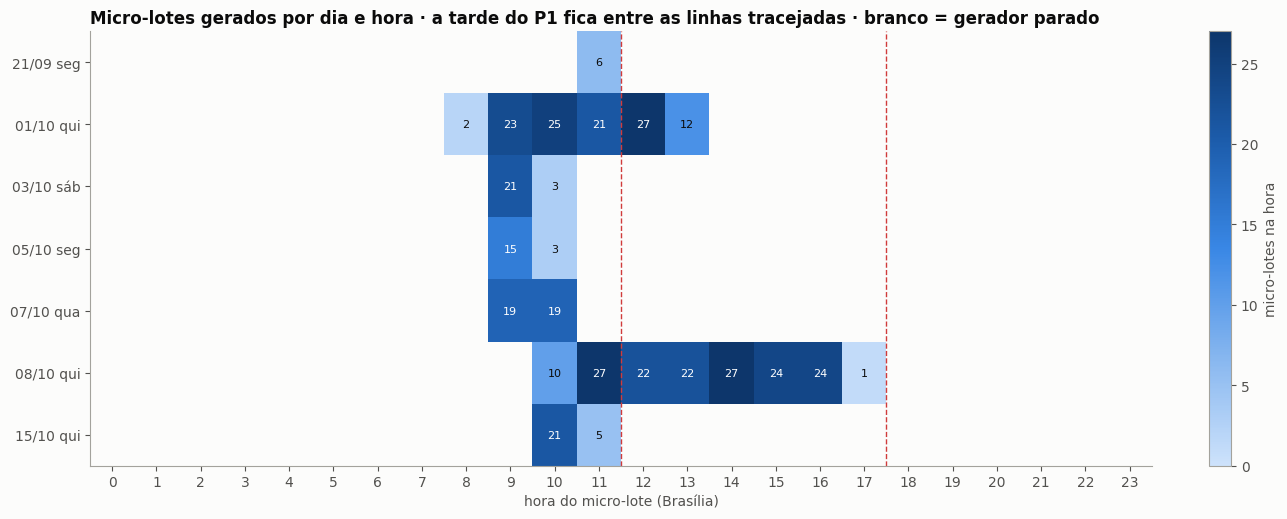

📌 Leitura
   • 379 micro-lotes em 7 dias e 23 horas distintas, de 21/09/2026 11:22 a 15/10/2026 11:08.
   • Quando o gerador roda, sai um micro-lote a cada 2,0 min (mediana).
   • Nenhum micro-lote novo há 24 dias (hoje: 08/11/2026).
   • Produtos e categorias só aparecem a partir de 01/10: o catálogo usado é a versão mais recente de cada SKU.
   • 0 micro-lotes vieram vazios (somando as 4 tabelas).


In [0]:
secao("1.1", "De onde vêm os dados")
fontes = pd.DataFrame([{"tabela": TABELAS[n], "micro_lotes": len(por_tabela[n]),
                        "micro_lotes_vazios": len(por_tabela[n]) - (brutos[n]["arquivo_origem"].nunique() if len(brutos[n]) else 0),
                        "linhas": len(brutos[n]), "colunas": len([c for c in brutos[n].columns if c not in ("arquivo_origem", "janela")]),
                        "primeiro_micro_lote": momento_janela(pd.Series(por_tabela[n], dtype=str)).min(),
                        "ultimo_micro_lote": momento_janela(pd.Series(por_tabela[n], dtype=str)).max()} for n in TABELAS])
exibir(fontes, "Micro-lotes por tabela")

mapa = lotes.pivot_table(index="data", columns="hora", values="arquivo", aggfunc="count").reindex(columns=range(24))
valores = mapa.values.astype(float)
fig, eixo = plt.subplots(figsize=(13, 0.5 * len(mapa) + 1.8))
imagem = eixo.imshow(valores, aspect="auto", cmap=AZUL, vmin=0)
for (i, j), v in np.ndenumerate(valores):
    if not np.isnan(v):
        eixo.text(j, i, int(v), ha="center", va="center", fontsize=8, color="white" if v > 0.55 * np.nanmax(valores) else "#0b0b0b")
eixo.set_yticks(range(len(mapa)), [dia_txt(d) for d in mapa.index])
eixo.set_xticks(range(24), range(24))
for limite in (HORA_PREVISAO - 0.5, FIM_TARDE - 0.5):
    eixo.axvline(limite, color=ERRO_COR, linestyle="--", linewidth=1)
eixo.grid(False)
eixo.set_xlabel("hora do micro-lote (Brasília)")
eixo.set_title("Micro-lotes gerados por dia e hora · a tarde do P1 fica entre as linhas tracejadas · branco = gerador parado")
plt.colorbar(imagem, ax=eixo, label="micro-lotes na hora", fraction=0.025)
plt.tight_layout()
mostrar()

intervalos = lotes.sort_values("janela").groupby("data")["janela"].diff().dt.total_seconds().div(60).dropna()
inicio_catalogo = fontes.set_index("tabela").loc[TABELAS["produtos"], "primeiro_micro_lote"]
leitura(f"{br(len(lotes))} micro-lotes em {DIAS_COM_DADO} dias e {len(horas_com_lote)} horas distintas, de {PRIMEIRO_LOTE:%d/%m/%Y %H:%M} a {ULTIMO_LOTE:%d/%m/%Y %H:%M}.",
        f"Quando o gerador roda, sai um micro-lote a cada {br(intervalos.median(), 1)} min (mediana).",
        f"Nenhum micro-lote novo há {DIAS_SEM_DADO} dias (hoje: {AGORA:%d/%m/%Y}).",
        f"Produtos e categorias só aparecem a partir de {inicio_catalogo:%d/%m}: o catálogo usado é a versão mais recente de cada SKU.",
        f"{int(fontes['micro_lotes_vazios'].sum())} micro-lotes vieram vazios (somando as 4 tabelas).")

## 1.2 Conhecendo a tabela de itens
Uma linha = **um produto dentro de um pedido**. A tabela liga o pedido (`id_pedido`) ao produto (`sku`) e traz quantidade, preço e desconto.
**O que observar:** tipos, vazios, faixas de valores e exemplos reais.

In [0]:
secao("1.2", "Conhecendo a tabela de itens")
SIGNIFICADO = {"id_item_pedido": "identificador do item (chave)", "id_pedido": "pedido do item → ecommerce_pedidos",
               "sku": "código do produto → ecommerce_produtos", "quantidade": "unidades compradas",
               "preco_unitario": "preço de uma unidade (R$)", "desconto_aplicado": "desconto por unidade (R$) · ver 1.5"}


def faixa(serie, funcao):
    try:
        return str(funcao(serie.dropna()))[:30] if serie.notna().any() else "—"
    except TypeError:
        return "tipos misturados"


perfil = pd.DataFrame([{"coluna": c, "tipo": str(brutos["itens"][c].dtype), "significado": SIGNIFICADO[c],
                        "vazios": int(itens[c].isna().sum()), "distintos": int(itens[c].nunique()),
                        "mínimo": faixa(itens[c], min), "máximo": faixa(itens[c], max),
                        "exemplo": str(itens[c].dropna().iloc[0]) if itens[c].notna().any() else "—"} for c in COLUNAS_ITENS])
exibir(perfil, "Colunas da tabela de itens")
display(itens[COLUNAS_ITENS + ["categoria"]].sample(min(8, len(itens)), random_state=7))
leitura(f"{len(COLUNAS_ITENS)} colunas, {br(len(itens))} linhas: {br(itens['id_pedido'].nunique())} pedidos e {br(itens['sku'].nunique())} SKUs distintos.",
        f"Nenhuma coluna da tabela tem vazio." if perfil["vazios"].sum() == 0 else f"{br(perfil['vazios'].sum())} valores vazios no total.",
        f"Quantidade de {br(itens['quantidade'].min())} a {br(itens['quantidade'].max())} · preço de {reais(itens['preco_unitario'].min())} a {reais(itens['preco_unitario'].max())}"
        + (": há valores ≤ 0 (ver 1.3)." if (itens["quantidade"] <= 0).any() or (itens["preco_unitario"] <= 0).any() else "."))

coluna,tipo,significado,vazios,distintos,mínimo,máximo,exemplo
id_item_pedido,Int64,identificador do item (chave),0,14196,17900005590,17920732803,17900005590
id_pedido,Int64,pedido do item → ecommerce_pedidos,0,2375,1790000559,1792073280,1790000559
sku,object,código do produto → ecommerce_produtos,0,3075,absorventes-always-16un-comaba,vinhostintobrancorose-salton-0,sabonetesbarraliquido-granado-1un-florais
quantidade,int64,unidades compradas,0,7,0,12,2
preco_unitario,float64,preço de uma unidade (R$),0,4227,-299.99,5292.0,24.68
desconto_aplicado,float64,desconto por unidade (R$) · ver 1.5,0,1054,-33.84,673.4,0.0


id_item_pedido,id_pedido,sku,quantidade,preco_unitario,desconto_aplicado,categoria
17914750813,1791475083,desinfetantes-lysoform-2l-pinho,1,35.24,37.72,Desinfetantes
17908726827,1790872684,areiasanitaria-pipicat-10kg-aglomerante,2,31.01,0.0,Areia Sanitária
17913800442,1791380047,amaciantes-comfort-2l-hipoalergenico,2,35.82,0.0,Amaciantes
17908645203,1790864520,petiscos-magnus-005kg-ossinho,1,28.15,0.0,Petiscos
17908702810,1790870281,fosforosacendedores-qualita-1un,1,26.98,0.0,Fósforos & Acendedores
17912048516,1791204852,aguamineralcomesemgas-crystal-05l-comgas,6,14.94,0.0,Água Mineral (com e sem gás)
17908614061,1790861413,racaocaes-golden-15kg-senior,1,96.52,0.0,Ração Cães
17908660805,1790866081,sabonetesbarraliquido-dove-6un-hidratante,1,9.66,0.0,"Sabonetes (Barra, Líquido)"


📌 Leitura
   • 6 colunas, 14.196 linhas: 2.375 pedidos e 3.075 SKUs distintos.
   • Nenhuma coluna da tabela tem vazio.
   • Quantidade de 0 a 12 · preço de R$ -299,99 a R$ 5.292,00: há valores ≤ 0 (ver 1.3).


## 1.3 Qualidade dos dados
Regras básicas de um item de pedido. Nada é apagado: itens com quantidade ≤ 0, preço ≤ 0 ou desconto < 0 recebem a marca `item_invalido`
(continuam no valor do pedido, que os inclui, e saem do mix e das médias das features).
**O que observar:** quanto do total cada problema representa e se ele se repete todos os dias (sujeira injetada pelo gerador) ou é pontual.

regra,itens,pct_itens,pedidos_afetados,marcado_item_invalido,status
id_item_pedido repetido,0,0.0,0,não,✅ ok
linha idêntica em mais de um micro-lote,0,0.0,0,não,✅ ok
id_pedido vazio,0,0.0,0,não,✅ ok
sku vazio,0,0.0,0,não,✅ ok
quantidade ≤ 0,499,3.52,424,sim,⚠️ atenção
preco_unitario ≤ 0,200,1.41,189,sim,⚠️ atenção
desconto_aplicado < 0,11,0.08,11,sim,⚠️ atenção
desconto maior que o preço,679,4.78,578,não,⚠️ atenção


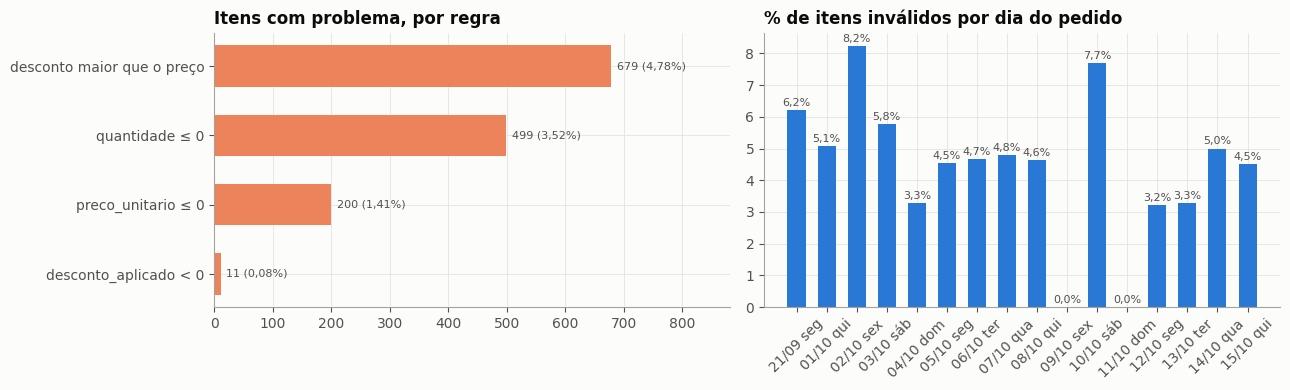

id_item_pedido,id_pedido,sku,quantidade,preco_unitario,desconto_aplicado,categoria
17900007600,1790000760,geleias-predilecta-025kg-morango,0,8.85,0.0,Geleias
17900007611,1790000762,sacosdelixo-bomsaco-50un-40l,0,22.76,0.0,Sacos de Lixo
17900007612,1790000762,papeltoalha-scott-2un-altaabsorcao,0,16.03,17.97,Papel Toalha
17900008809,1790000882,panetonescolombassazonal-marcapropria-075kg-gotasd,0,29.54,36.17,Panetones & Colombas (Sazonal)
17900010005,1790001000,amaciantes-ype-2l-classico,0,-25.7,0.0,Amaciantes
17900010020,1790001002,cremedental-colgate-018kg-triplaacao,0,22.56,1.13,Creme Dental
17900011209,1790001121,sabaopoliquido-omo-1kg-liquido,3,-11.25,0.0,"Sabão (Pó, Líquido)"
17900011215,1790001122,desinfetantes-lysoform-05l-lavanda,0,27.0,29.47,Desinfetantes


📌 Leitura
   • 690 itens inválidos (4,9%) em 565 pedidos (23,8% dos pedidos).
   • O % de itens inválidos vai de 0,0% a 8,2% por dia e aparece em 14 de 16 dias.
   • Nos pedidos com item inválido, a soma dos itens ainda bate com o valor_total em 100,0%: o valor_total inclui esses itens, por isso não os apagamos.
   • Chaves: 0 ids repetidos, 0 chaves vazias.


In [0]:
secao("1.3", "Qualidade dos dados")
REGRAS_INVALIDO = ["quantidade ≤ 0", "preco_unitario ≤ 0", "desconto_aplicado < 0"]
regras = {"id_item_pedido repetido": itens["id_item_pedido"].duplicated(keep=False),
          "linha idêntica em mais de um micro-lote": itens.duplicated(subset=COLUNAS_ITENS, keep=False),
          "id_pedido vazio": itens["id_pedido"].isna(), "sku vazio": itens["sku"].isna(),
          "quantidade ≤ 0": itens["quantidade"] <= 0, "preco_unitario ≤ 0": itens["preco_unitario"] <= 0,
          "desconto_aplicado < 0": itens["desconto_aplicado"] < 0,
          "desconto maior que o preço": itens["desconto_aplicado"] > itens["preco_unitario"]}
qualidade = pd.DataFrame([{"regra": r, "itens": int(m.sum()), "pct_itens": round(100 * m.mean(), 2),
                           "pedidos_afetados": int(itens.loc[m, "id_pedido"].nunique()),
                           "marcado_item_invalido": "sim" if r in REGRAS_INVALIDO else "não",
                           "status": selo(m.sum() == 0)} for r, m in regras.items()])
exibir(qualidade, "Regras de qualidade")

por_dia = itens.assign(dia=itens["local"].dt.normalize()).groupby("dia")["item_invalido"].mean().mul(100)
problemas = qualidade[qualidade["itens"] > 0].sort_values("itens")
fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(13, 4))
if len(problemas):
    barras = eixo1.barh(problemas["regra"], problemas["itens"], color=SERIO_COR, height=0.6)
    rotular(eixo1, barras, [f"{br(n)} ({pct(p, 2)})" for n, p in zip(problemas["itens"], problemas["pct_itens"])], horizontal=True)
    eixo1.set_xlim(0, problemas["itens"].max() * 1.3)
else:
    eixo1.text(0.5, 0.5, "nenhum problema encontrado", ha="center", transform=eixo1.transAxes)
eixo1.set_title("Itens com problema, por regra")
barras = eixo2.bar([dia_txt(d) for d in por_dia.index], por_dia.values, color=CORES[0], width=0.6)
rotular(eixo2, barras, [pct(v) for v in por_dia.values])
eixo2.set_title("% de itens inválidos por dia do pedido")
eixo2.tick_params(axis="x", rotation=45)
plt.tight_layout()
mostrar()

afetados = itens.loc[itens["item_invalido"], "id_pedido"].unique()
bate_afetados = 100 * ((conferencia_valor["valor_liquido"] - conferencia_valor["valor_total"]).abs() <= TOLERANCIA_VALOR)[conferencia_valor.index.isin(afetados)].mean() if len(afetados) else 100.0
display(itens.loc[itens["item_invalido"], COLUNAS_ITENS + ["categoria"]].head(8))
leitura(f"{br(itens['item_invalido'].sum())} itens inválidos ({pct(PCT_INVALIDOS)}) em {br(len(afetados))} pedidos ({pct(100 * len(afetados) / len(pedidos))} dos pedidos).",
        f"O % de itens inválidos vai de {pct(por_dia.min())} a {pct(por_dia.max())} por dia e aparece em {int((por_dia > 0).sum())} de {len(por_dia)} dias"
        + (": problema constante, típico de sujeira gerada de propósito." if (por_dia > 0).all() else "."),
        f"Nos pedidos com item inválido, a soma dos itens ainda bate com o valor_total em {pct(bate_afetados)}: o valor_total inclui esses itens, por isso não os apagamos.",
        f"Chaves: {N_DUP} ids repetidos, {N_CHAVE_VAZIA} chaves vazias.")

## 1.4 Ligações com pedidos, produtos e categorias
```text
ecommerce_pedidos ──id_pedido──▶ ecommerce_itens_pedido ──sku──▶ ecommerce_produtos ──id_categoria──▶ ecommerce_categorias
```
**O que observar:** se toda chave encontra o seu par, se o item chega no mesmo micro-lote do pedido e quantos pedidos foram aprovados no pipeline (Silver).

ligacao,cobertura_pct,status
itens com pedido no raw,100.0,✅ ok
pedidos com ao menos 1 item,100.0,✅ ok
itens no mesmo micro-lote do pedido,100.0,✅ ok
itens com SKU no catálogo,100.0,✅ ok
produtos com categoria cadastrada,100.0,✅ ok


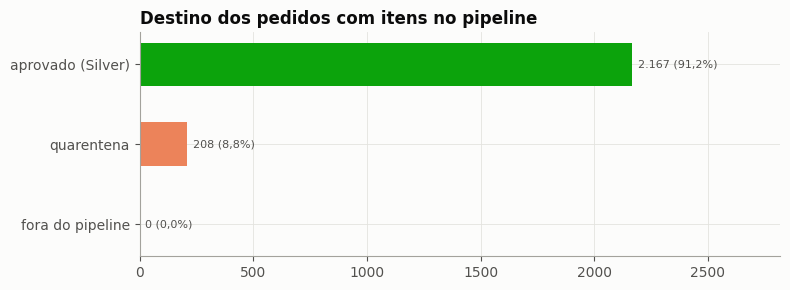

📌 Leitura
   • Todas as ligações com cobertura ≥ 99%.
   • 100,0% dos itens chegam no mesmo micro-lote do pedido: dá para montar as features a cada micro-lote, sem esperar.
   • 91,2% dos pedidos foram aprovados; 208 foram para a quarentena. A receita das features usa só os aprovados.


In [0]:
secao("1.4", "Ligações com pedidos, produtos e categorias")
mesmo_lote = itens[["id_pedido", "arquivo_origem"]].merge(pedidos[["id_pedido", "arquivo_origem"]], on="id_pedido", suffixes=("_item", "_pedido"))
pasta = lambda s: s.str.rsplit("/", n=1).str[0]
ligacoes = pd.DataFrame([
    ("itens com pedido no raw", 100 * itens["id_pedido"].isin(set(pedidos["id_pedido"])).mean()),
    ("pedidos com ao menos 1 item", 100 * pedidos["id_pedido"].isin(set(itens["id_pedido"])).mean()),
    ("itens no mesmo micro-lote do pedido", 100 * (pasta(mesmo_lote["arquivo_origem_item"]) == pasta(mesmo_lote["arquivo_origem_pedido"])).mean()),
    ("itens com SKU no catálogo", 100 * itens["sku"].isin(set(produtos["sku"])).mean()),
    ("produtos com categoria cadastrada", 100 * produtos["id_categoria"].isin(set(categorias["id_categoria"])).mean()),
], columns=["ligacao", "cobertura_pct"]).round(2)
ligacoes["status"] = [selo(v >= 99) for v in ligacoes["cobertura_pct"]]
destino = pedidos["destino"].value_counts().reindex(["aprovado (Silver)", "quarentena", "fora do pipeline"], fill_value=0)
_registro()["tabelas"].append(("Destino dos pedidos", destino.rename_axis("destino").reset_index(name="pedidos")))
exibir(ligacoes, "Cobertura das ligações")

fig, eixo = plt.subplots(figsize=(8, 3))
barras = eixo.barh(destino.index[::-1], destino.values[::-1], color=[CINZA, SERIO_COR, OK_COR], height=0.55)
rotular(eixo, barras, [f"{br(v)} ({pct(100 * v / destino.sum())})" for v in destino.values[::-1]], horizontal=True)
eixo.set_xlim(0, destino.max() * 1.3)
eixo.set_title("Destino dos pedidos com itens no pipeline")
plt.tight_layout()
mostrar()
leitura(f"Todas as ligações com cobertura ≥ 99%." if (ligacoes["cobertura_pct"] >= 99).all()
        else f"Ligações abaixo de 99%: {', '.join(ligacoes.loc[ligacoes['cobertura_pct'] < 99, 'ligacao'])}.",
        f"{pct(ligacoes.loc[2, 'cobertura_pct'])} dos itens chegam no mesmo micro-lote do pedido: dá para montar as features a cada micro-lote, sem esperar.",
        f"{pct(100 * destino['aprovado (Silver)'] / destino.sum())} dos pedidos foram aprovados; {br(destino['quarentena'])} foram para a quarentena. "
        "A receita das features usa só os aprovados.")

## 1.5 Como o valor do pedido é formado
Somamos os itens de cada pedido e testamos as contas possíveis: com e sem desconto, desconto por linha, por unidade ou em %, com e sem frete.
A conta que reproduz o `valor_total` diz **o que é o `desconto_aplicado`** e **se o frete entra** — e define como as features de valor são calculadas.

conta,pedidos_que_batem_pct,diferenca_mediana_R$
Σ qtd × preço − desconto por unidade,100.0,0.0
Σ qtd × preço − desconto da linha,69.68,0.0
Σ qtd × preço sem desconto,38.99,1.82
Σ qtd × preço × (1 − desconto em %),38.99,31.95
Σ qtd × preço − desconto por unidade + frete,21.98,15.13
Σ qtd × preço − desconto da linha + frete,12.59,16.44
Σ qtd × preço sem desconto + frete,5.94,20.23
Σ qtd × preço × (1 − desconto em %) + frete,5.94,23.3


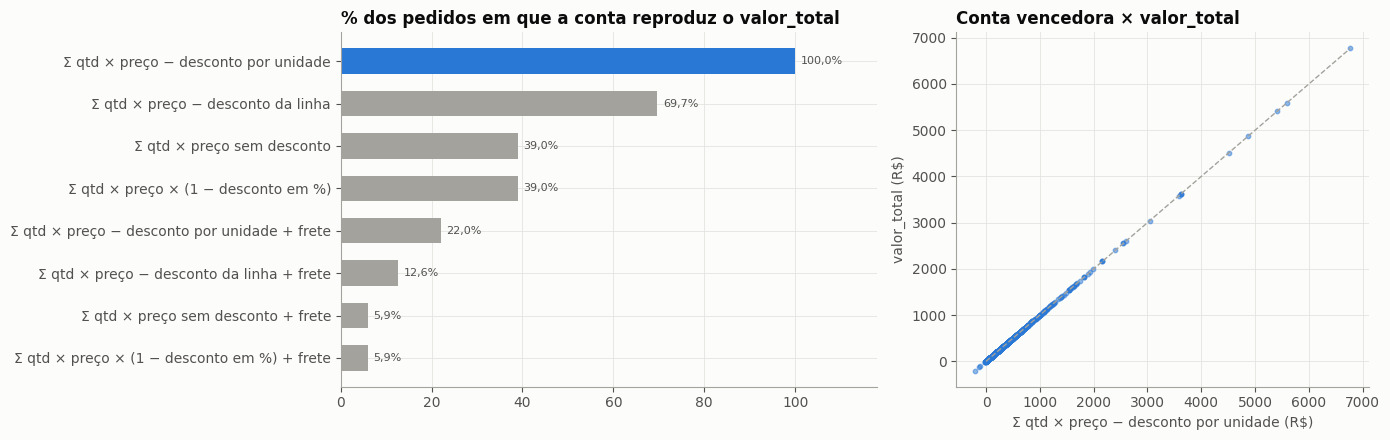

📌 Leitura
   • Vencedora: valor_total = Σ qtd × preço − desconto por unidade, em 100,0% dos pedidos.
   • Com frete somado, a mesma conta bate em só 22,0%: o frete (média de R$ 13,55) fica fora do valor_total.
   • Desconto tratado como valor da linha bate em 69,7%: o desconto_aplicado é por unidade.
   • Nas features: valor_liquido = Σ quantidade × (preço − desconto); receita = valor_total; frete em coluna separada.


In [0]:
secao("1.5", "Como o valor do pedido é formado")
linha = itens.assign(desc_linha=itens["desconto_aplicado"].fillna(0), desc_unidade=itens["desconto_item"],
                     desc_pct=itens["valor_bruto"] * itens["desconto_aplicado"].fillna(0))
somas = linha.groupby("id_pedido")[["valor_bruto", "desc_linha", "desc_unidade", "desc_pct"]].sum()
conferencia = somas.join(pedidos.set_index("id_pedido")[["valor_total", "valor_frete"]], how="inner").astype(float)
contas = {}
for nome_desc, coluna_desc in [("sem desconto", None), ("− desconto da linha", "desc_linha"),
                               ("− desconto por unidade", "desc_unidade"), ("× (1 − desconto em %)", "desc_pct")]:
    base = conferencia["valor_bruto"] - (conferencia[coluna_desc] if coluna_desc else 0)
    contas[f"Σ qtd × preço {nome_desc}"] = base
    contas[f"Σ qtd × preço {nome_desc} + frete"] = base + conferencia["valor_frete"].fillna(0)
testes = (pd.DataFrame([{"conta": n, "pedidos_que_batem_pct": round(100 * ((conferencia["valor_total"] - v).abs() <= TOLERANCIA_VALOR).mean(), 2),
                         "diferenca_mediana_R$": round((conferencia["valor_total"] - v).abs().median(), 2)} for n, v in contas.items()])
          .sort_values("pedidos_que_batem_pct", ascending=False).reset_index(drop=True))
MELHOR = testes.loc[0, "conta"]
MELHOR_BASE = MELHOR.removesuffix(" + frete")
exibir(testes, "Contas testadas para o valor_total")

fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
ordem = testes.iloc[::-1]
barras = eixo1.barh(ordem["conta"], ordem["pedidos_que_batem_pct"], color=[CORES[0] if c == MELHOR else CINZA for c in ordem["conta"]], height=0.6)
rotular(eixo1, barras, [pct(v) for v in ordem["pedidos_que_batem_pct"]], horizontal=True)
eixo1.set_xlim(0, 118)
eixo1.set_title("% dos pedidos em que a conta reproduz o valor_total")
eixo2.scatter(contas[MELHOR], conferencia["valor_total"], s=10, alpha=0.5, color=CORES[0])
limite = float(conferencia["valor_total"].max())
eixo2.plot([0, limite], [0, limite], color=CINZA, linestyle="--", linewidth=1)
eixo2.set_xlabel(f"{MELHOR} (R$)")
eixo2.set_ylabel("valor_total (R$)")
eixo2.set_title("Conta vencedora × valor_total")
plt.tight_layout()
mostrar()
pct_conta = testes.set_index("conta")["pedidos_que_batem_pct"]
leitura(f"Vencedora: valor_total = {MELHOR}, em {pct(pct_conta[MELHOR])} dos pedidos.",
        (f"Com frete somado, a mesma conta bate em só {pct(pct_conta[MELHOR + ' + frete'])}: o frete (média de {reais(pedidos['valor_frete'].mean())}) fica fora do valor_total."
         if MELHOR == MELHOR_BASE else f"Sem o frete, a mesma conta bate em só {pct(pct_conta[MELHOR_BASE])}: o frete entra no valor_total."),
        f"Desconto tratado como valor da linha bate em {pct(pct_conta['Σ qtd × preço − desconto da linha'])}: o desconto_aplicado é por unidade.",
        "Nas features: valor_liquido = Σ quantidade × (preço − desconto); receita = valor_total; frete em coluna separada.")

## 1.6 Distribuições
Itens por pedido, quantidade por item, preço unitário e valor do pedido.
**O que observar:** forma das distribuições (assimetria, caudas) e onde estão os valores inválidos.

medida,itens por pedido,SKUs por pedido,quantidade por item,"preço unitário (R$, válidos)","desconto por unidade (R$, itens com desconto)",valor do pedido (R$),frete (R$)
count,2375.0,2375.0,14196.0,13506.0,2596.0,2375.0,2375.0
mean,5.98,5.98,1.49,33.78,10.24,261.19,13.55
std,4.48,4.48,1.14,105.21,28.21,395.03,8.17
min,1.0,1.0,0.0,2.32,0.18,-200.34,0.0
25%,3.0,3.0,1.0,12.57,1.28,92.04,10.46
50%,5.0,5.0,1.0,20.35,2.56,166.19,15.13
75%,7.0,7.0,2.0,28.72,7.4,288.82,20.13
95%,15.0,15.0,3.0,84.88,37.4,757.85,23.95
max,30.0,30.0,12.0,5292.0,673.4,6767.39,25.0


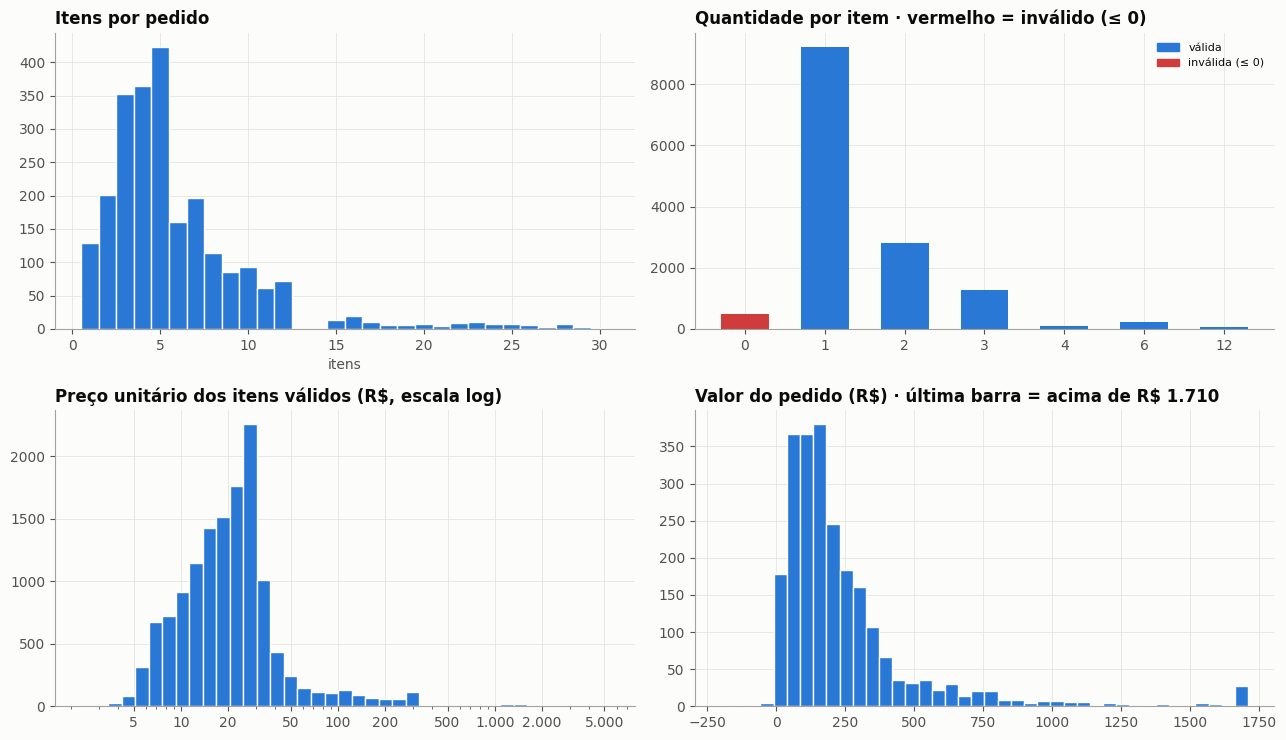

📌 Leitura
   • Pedido típico: 5 itens (mediana), 5,4% dos pedidos têm 1 item só; 5% passam de 15 itens.
   • Preço unitário mediano R$ 20,35; 5% dos itens custam mais de R$ 84,88 (cauda longa → escala log).
   • Valor do pedido: mediana R$ 166,19, média R$ 261,19 (média bem acima da mediana = poucos pedidos grandes).
   • 18,3% dos itens têm desconto; mediana de R$ 2,56 por unidade.


In [0]:
secao("1.6", "Distribuições")
com_desconto = itens["com_desconto"]
resumo = pd.concat({"itens por pedido": por_pedido["n_itens"].describe(percentiles=[.25, .5, .75, .95]),
                    "SKUs por pedido": por_pedido["n_skus"].describe(percentiles=[.25, .5, .75, .95]),
                    "quantidade por item": itens["quantidade"].describe(percentiles=[.25, .5, .75, .95]),
                    "preço unitário (R$, válidos)": validos["preco_unitario"].describe(percentiles=[.25, .5, .75, .95]),
                    "desconto por unidade (R$, itens com desconto)": itens.loc[com_desconto, "desconto_aplicado"].describe(percentiles=[.25, .5, .75, .95]),
                    "valor do pedido (R$)": por_pedido["valor_total"].describe(percentiles=[.25, .5, .75, .95]),
                    "frete (R$)": por_pedido["valor_frete"].describe(percentiles=[.25, .5, .75, .95])}, axis=1).round(2)
exibir(resumo.reset_index().rename(columns={"index": "medida"}), "Resumo das distribuições")

fig, eixos = plt.subplots(2, 2, figsize=(13, 7.5))
eixos[0, 0].hist(por_pedido["n_itens"], bins=np.arange(0.5, por_pedido["n_itens"].max() + 1.5), color=CORES[0], edgecolor=FUNDO)
eixos[0, 0].set_title("Itens por pedido")
eixos[0, 0].set_xlabel("itens")
qtd = itens["quantidade"].value_counts()
qtd = qtd[qtd.index.isin(qtd.nlargest(15).index)].sort_index()
barras = eixos[0, 1].bar(qtd.index.astype(str), qtd.values, color=[ERRO_COR if q <= 0 else CORES[0] for q in qtd.index], width=0.6)
eixos[0, 1].set_title("Quantidade por item · vermelho = inválido (≤ 0)")
eixos[0, 1].legend(handles=[Patch(color=CORES[0], label="válida"), Patch(color=ERRO_COR, label="inválida (≤ 0)")], fontsize=8)
precos = validos["preco_unitario"]
eixos[1, 0].hist(precos, bins=np.logspace(np.log10(max(precos.min(), 0.01)), np.log10(precos.max()), 40), color=CORES[0], edgecolor=FUNDO)
eixos[1, 0].set_xscale("log")
eixos[1, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v, 0) if v >= 1 else br(v, 2)))
eixos[1, 0].xaxis.set_minor_formatter(plt.NullFormatter())
eixos[1, 0].set_xticks([t for t in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000] if precos.min() <= t <= precos.max()])
eixos[1, 0].set_title("Preço unitário dos itens válidos (R$, escala log)")
teto = por_pedido["valor_total"].quantile(0.99)
eixos[1, 1].hist(por_pedido["valor_total"].clip(upper=teto), bins=40, color=CORES[0], edgecolor=FUNDO)
eixos[1, 1].set_title(f"Valor do pedido (R$) · última barra = acima de {reais(teto, 0)}")
plt.tight_layout()
mostrar()
leitura(f"Pedido típico: {br(por_pedido['n_itens'].median())} itens (mediana), {pct(100 * (por_pedido['n_itens'] == 1).mean())} dos pedidos têm 1 item só; 5% passam de {br(por_pedido['n_itens'].quantile(.95))} itens.",
        f"Preço unitário mediano {reais(precos.median())}; 5% dos itens custam mais de {reais(precos.quantile(.95))} (cauda longa → escala log).",
        f"Valor do pedido: mediana {reais(por_pedido['valor_total'].median())}, média {reais(por_pedido['valor_total'].mean())}"
        + (" (média bem acima da mediana = poucos pedidos grandes)." if por_pedido["valor_total"].mean() > 1.2 * por_pedido["valor_total"].median() else "."),
        f"{pct(100 * com_desconto.mean())} dos itens têm desconto; mediana de {reais(itens.loc[com_desconto, 'desconto_aplicado'].median())} por unidade.")

## 1.7 Produtos e categorias
**O que observar:** quais categorias concentram o valor vendido (base do *mix de categorias* do P1), quanto do catálogo vende e quão concentradas são as vendas por SKU.

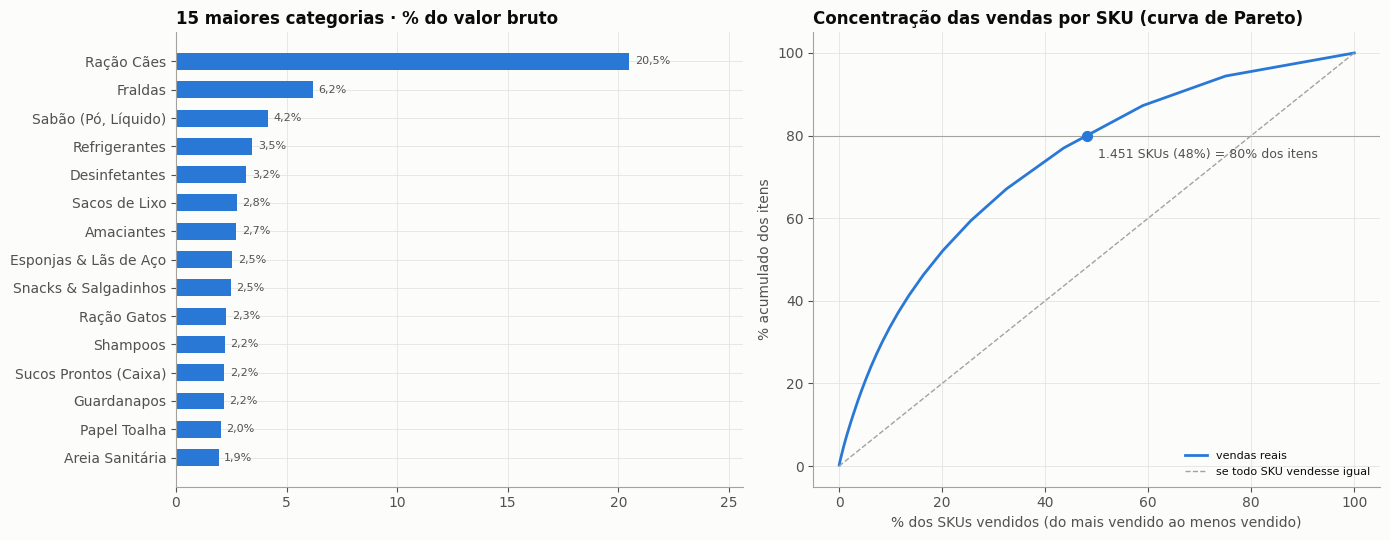

categoria,itens,pedidos,quantidade,valor_bruto,preco_medio,pct_itens_com_desconto,pct_valor,pct_acumulado
Ração Cães,608,384,824,136091.99,165.79,17.43,20.5,20.5
Fraldas,230,178,344,41012.09,125.81,20.87,6.18,26.68
"Sabão (Pó, Líquido)",676,454,1004,27679.52,27.23,17.6,4.17,30.84
Refrigerantes,387,239,1745,22939.99,11.51,18.6,3.46,34.3
Desinfetantes,651,423,910,21104.7,23.99,18.43,3.18,37.48
Sacos de Lixo,494,363,710,18260.56,26.27,22.06,2.75,40.23
Amaciantes,500,367,778,18058.88,24.49,21.0,2.72,42.95
Esponjas & Lãs de Aço,392,302,556,16876.59,29.22,17.6,2.54,45.49
Snacks & Salgadinhos,159,141,217,16394.7,51.84,22.01,2.47,47.96
Ração Gatos,332,251,459,15092.74,33.76,19.88,2.27,50.23


sku,itens,quantidade,valor_bruto,nome_produto,nome_marca,categoria
aguasanitaria-brilux-5l,33,40,1575.24,Água Sanitária 5L - Brilux,Brilux,Água Sanitária
desinfetantes-veja-1l-lavanda,32,42,2139.04,Desinfetantes Lavanda 1L - Veja,Veja,Desinfetantes
sacosdelixo-embalixo-20un-pia,31,48,2235.13,Sacos de Lixo Pia 20un - Embalixo,Embalixo,Sacos de Lixo
amaciantes-downy-1l-concentradoazul,28,38,735.76,Amaciantes Concentrado Azul 1L - Downy,Downy,Amaciantes
guardanapos-mili-100un-folhadupla,26,33,1659.28,Guardanapos Folha Dupla 100un - Mili,Mili,Guardanapos
desinfetantes-veja-2l-cloroativogel,24,33,812.82,Desinfetantes Cloro Ativo (Gel) 2L - Veja,Veja,Desinfetantes
amaciantes-downy-2l-classico,23,28,775.13,Amaciantes Clássico 2L - Downy,Downy,Amaciantes
sacosdelixo-embalixo-20un-60l,23,34,965.16,Sacos de Lixo 60L 20un - Embalixo,Embalixo,Sacos de Lixo
esponjaslasdeaco-scotchbrite-8un-esponjanaorisca,23,30,464.04,Esponjas & Lãs de Aço Esponja Não Risca 8un - Scotch-Brite,Scotch-Brite,Esponjas & Lãs de Aço
sabaopoliquido-ariel-3kg-toquedecomfort,23,44,902.28,"Sabão (Pó, Líquido) Toque de Comfort 3kg - Ariel",Ariel,"Sabão (Pó, Líquido)"


nome_categoria_pai,categorias,itens,valor_bruto,pct_valor
Pets,6,1480,173331.08,26.1
Limpeza,14,3651,130830.46,19.7
Higiene & Cuidados Pessoais,17,2229,73600.59,11.1
"Matinais, Doces & Biscoitos",22,1909,70676.98,10.6
Bebidas,10,763,54394.71,8.2
Mundo Bebê,6,406,50913.79,7.7
Bazar & Utilidades,12,1300,50015.6,7.5
Mercearia Salgada (Complementos),9,741,25398.06,3.8
Mercearia Básica,9,453,14911.58,2.2
Adega & Destilados,6,257,12134.9,1.8


📌 Leitura
   • 123 categorias com venda; as 3 maiores (Ração Cães, Fraldas, Sabão (Pó, Líquido)) somam 31% do valor.
   • As 8 categorias com coluna própria nas features somam 45%; o resto vira 'Outras'.
   • 3.018 SKUs vendidos = 79% do catálogo. Metade dos itens vem de 566 SKUs e 80% de 1.451: venda espalhada, sem poucos campeões.
   • SKU mais vendido: aguasanitaria-brilux-5l (Água Sanitária 5L - Brilux), 33 itens.


In [0]:
secao("1.7", "Produtos e categorias")
por_categoria = (validos.groupby("categoria").agg(itens=("id_item_pedido", "count"), pedidos=("id_pedido", "nunique"),
                                                  quantidade=("quantidade", "sum"), valor_bruto=("valor_bruto", "sum"),
                                                  preco_medio=("preco_unitario", "mean"), pct_itens_com_desconto=("com_desconto", "mean"))
                 .sort_values("valor_bruto", ascending=False))
por_categoria["pct_valor"] = 100 * por_categoria["valor_bruto"] / por_categoria["valor_bruto"].sum()
por_categoria["pct_acumulado"] = por_categoria["pct_valor"].cumsum()
por_categoria["pct_itens_com_desconto"] *= 100
vendas_sku = validos.groupby("sku").agg(itens=("id_item_pedido", "count"), quantidade=("quantidade", "sum"),
                                        valor_bruto=("valor_bruto", "sum")).sort_values("itens", ascending=False)
acumulado = vendas_sku["itens"].cumsum() / vendas_sku["itens"].sum()
SKUS_50, SKUS_80 = int((acumulado < 0.5).sum() + 1), int((acumulado < 0.8).sum() + 1)
COBERTURA_CATALOGO = 100 * vendas_sku.index.isin(set(produtos["sku"])).sum() / max(produtos["sku"].nunique(), 1)

fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(14, 5.5))
maiores = por_categoria.head(TOP_CATEGORIAS_GRAFICO).iloc[::-1]
barras = eixo1.barh(maiores.index, maiores["pct_valor"], color=CORES[0], height=0.6)
rotular(eixo1, barras, [pct(v) for v in maiores["pct_valor"]], horizontal=True)
eixo1.set_xlim(0, maiores["pct_valor"].max() * 1.25)
eixo1.set_title(f"{TOP_CATEGORIAS_GRAFICO} maiores categorias · % do valor bruto")
x = 100 * np.arange(1, len(acumulado) + 1) / len(acumulado)
eixo2.plot(x, 100 * acumulado.values, color=CORES[0], linewidth=2, label="vendas reais")
eixo2.plot([0, 100], [0, 100], color=CINZA, linestyle="--", linewidth=1, label="se todo SKU vendesse igual")
eixo2.axhline(80, color=CINZA, linewidth=0.8)
eixo2.scatter([100 * SKUS_80 / len(acumulado)], [80], color=CORES[0], s=50, zorder=3)
eixo2.annotate(f"{br(SKUS_80)} SKUs ({pct(100 * SKUS_80 / len(acumulado), 0)}) = 80% dos itens", (100 * SKUS_80 / len(acumulado), 80),
               xytext=(8, -16), textcoords="offset points", fontsize=9, color=TEXTO_2)
eixo2.set_xlabel("% dos SKUs vendidos (do mais vendido ao menos vendido)")
eixo2.set_ylabel("% acumulado dos itens")
eixo2.set_title("Concentração das vendas por SKU (curva de Pareto)")
eixo2.legend(fontsize=8, loc="lower right")
plt.tight_layout()
mostrar()

exibir(por_categoria.head(20).round(2).reset_index(), "Maiores categorias", linhas=12)
colunas_nome = [c for c in ["nome_produto", "nome_marca", "categoria"] if c in validos.columns]
top_skus = vendas_sku.head(TOP_SKUS).join(validos.drop_duplicates("sku").set_index("sku")[colunas_nome]).reset_index()
exibir(top_skus.round(2), "SKUs mais vendidos", linhas=10)
if "nome_categoria_pai" in validos.columns:
    departamentos = (validos.groupby(validos["nome_categoria_pai"].fillna("sem departamento"))
                     .agg(categorias=("categoria", "nunique"), itens=("id_item_pedido", "count"), valor_bruto=("valor_bruto", "sum"))
                     .sort_values("valor_bruto", ascending=False))
    departamentos["pct_valor"] = (100 * departamentos["valor_bruto"] / departamentos["valor_bruto"].sum()).round(1)
    display(departamentos.head(15).round(2).reset_index())
leitura(f"{por_categoria.shape[0]} categorias com venda; as 3 maiores ({', '.join(por_categoria.index[:3])}) somam {pct(por_categoria['pct_valor'].head(3).sum(), 0)} do valor.",
        f"As {len([g for g in GRUPOS_MIX if g != 'outras'])} categorias com coluna própria nas features somam {pct(por_categoria['pct_valor'].head(len(GRUPOS_MIX) - 1).sum(), 0)}; o resto vira 'Outras'.",
        f"{br(len(vendas_sku))} SKUs vendidos = {pct(COBERTURA_CATALOGO, 0)} do catálogo. Metade dos itens vem de {br(SKUS_50)} SKUs e 80% de {br(SKUS_80)}: venda espalhada, sem poucos campeões.",
        f"SKU mais vendido: {top_skus.loc[0, 'sku']} ({top_skus.loc[0, colunas_nome[0]] if colunas_nome else ''}), {br(top_skus.loc[0, 'itens'])} itens.")

## 1.8 Padrões ao longo do dia
Como o gerador não roda em todas as horas, comparamos horas pela **média por hora observada** (soma ÷ nº de horas em que houve micro-lote), só com pedidos aprovados.
**O que observar:** horários de pico, ticket médio e — o mais importante para o P1 — se o **mix de categorias da manhã difere do da tarde**.

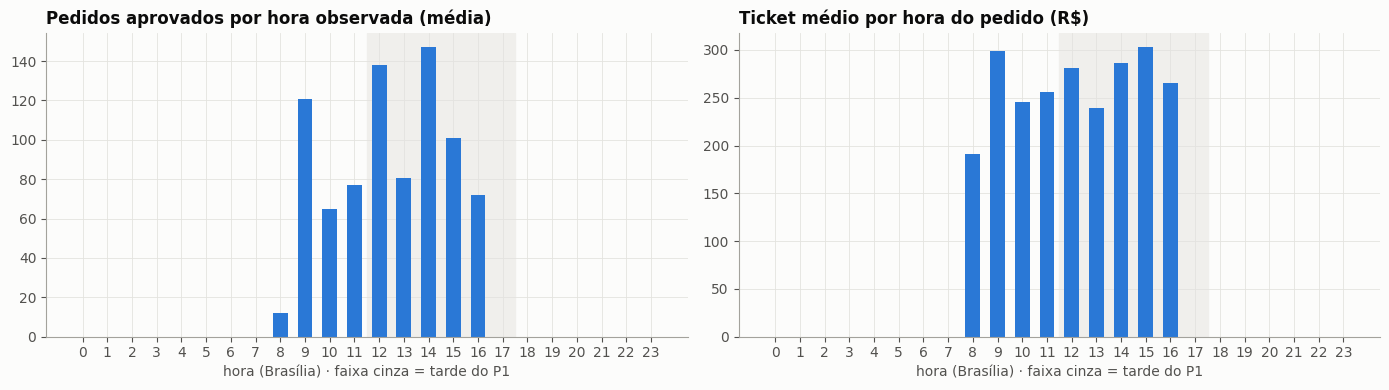

hora,pedidos,receita,horas_observadas,pedidos_por_hora,receita_por_hora,ticket_medio,itens_por_pedido
8,12.0,2299.37,1,12.0,2299.37,191.61,7.46
9,482.0,144298.91,4,120.5,36074.73,299.38,8.21
10,389.0,95517.3,6,64.83,15919.55,245.55,5.38
11,309.0,79008.78,4,77.25,19752.2,255.69,5.33
12,276.0,77597.91,2,138.0,38798.96,281.15,5.5
13,161.0,38451.17,2,80.5,19225.58,238.83,5.38
14,147.0,42073.39,1,147.0,42073.39,286.21,5.74
15,101.0,30580.52,1,101.0,30580.52,302.78,5.04
16,72.0,19110.39,1,72.0,19110.39,265.42,5.06
17,null,null,1,null,null,null,5.67


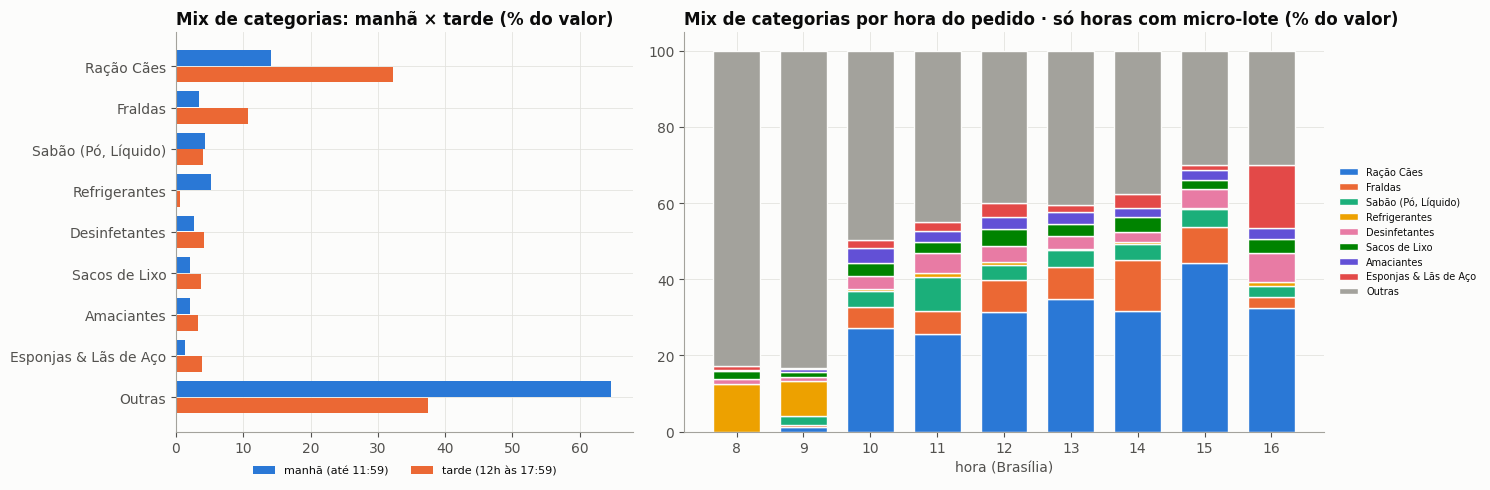

categoria,manha_pct,tarde_pct,diferenca_pp
Outras,64.69,37.53,-27.16
Ração Cães,14.14,32.2,18.06
Fraldas,3.38,10.7,7.31
Refrigerantes,5.19,0.65,-4.55
Esponjas & Lãs de Aço,1.28,3.9,2.62
Sacos de Lixo,2.16,3.68,1.52
Desinfetantes,2.72,4.13,1.4
Amaciantes,2.08,3.21,1.12
"Sabão (Pó, Líquido)",4.35,4.02,-0.33


📌 Leitura
   • Hora com mais pedidos (média por hora observada): 14h, com 147,0 pedidos.
   • Ticket médio vai de R$ 191,61 a R$ 302,78 conforme a hora.
   • Maior mudança de mix: Outras vai de 64,7% de manhã para 37,5% à tarde (-27,2 p.p.): o mix da manhã carrega informação sobre a tarde → feature do P1.
   • Horas observadas: 15 na manhã e 8 na tarde — poucas, então os padrões por hora são indicativos.
   • 10,1% dos pedidos aprovados (9,1% da receita) têm hora do pedido em horas sem micro-lote (pedido registrado antes de chegar ao lake): entram no mix manhã × tarde, mas ficam fora da grade horária das features.


In [0]:
secao("1.8", "Padrões ao longo do dia")
obs_hora = pd.Series([h.hour for h in horas_com_lote]).value_counts().reindex(range(24), fill_value=0)
ped_obs = pedidos[pedidos["aprovado"] & pedidos["hora_local"].isin(horas_com_lote)]
por_hora_dia = ped_obs.groupby(ped_obs["local"].dt.hour).agg(pedidos=("id_pedido", "nunique"), receita=("valor_total", "sum")).reindex(range(24))
por_hora_dia["horas_observadas"] = obs_hora
por_hora_dia["pedidos_por_hora"] = por_hora_dia["pedidos"] / obs_hora.replace(0, np.nan)
por_hora_dia["receita_por_hora"] = por_hora_dia["receita"] / obs_hora.replace(0, np.nan)
por_hora_dia["ticket_medio"] = por_hora_dia["receita"] / por_hora_dia["pedidos"]
itens_hora = por_pedido[por_pedido["aprovado"].astype(bool)].groupby("hora")["n_itens"].mean()
por_hora_dia["itens_por_pedido"] = itens_hora.reindex(range(24))

fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(14, 4))
for eixo, coluna, titulo in [(eixo1, "pedidos_por_hora", "Pedidos aprovados por hora observada (média)"),
                             (eixo2, "ticket_medio", "Ticket médio por hora do pedido (R$)")]:
    eixo.axvspan(HORA_PREVISAO - 0.5, FIM_TARDE - 0.5, color="#f0efec", zorder=0)
    eixo.bar(range(24), por_hora_dia[coluna].fillna(0), color=CORES[0], width=0.6)
    eixo.set_xticks(range(24))
    eixo.set_xlabel("hora (Brasília) · faixa cinza = tarde do P1")
    eixo.set_title(titulo)
plt.tight_layout()
mostrar()
display(por_hora_dia[por_hora_dia["horas_observadas"] > 0].round(2).reset_index(names="hora"))

mix_periodo = (pd.crosstab(validos.loc[validos["aprovado"] == True, "periodo"], validos.loc[validos["aprovado"] == True, "grupo_mix"],
                           values=validos.loc[validos["aprovado"] == True, "valor_bruto"], aggfunc="sum", normalize="index")
               .mul(100).reindex(columns=GRUPOS_MIX, fill_value=0))
tem_dois = {"manhã", "tarde"} <= set(mix_periodo.index)
if tem_dois:
    comparacao = pd.DataFrame({"categoria": [NOME_GRUPO.get(g, g) for g in GRUPOS_MIX], "manha_pct": mix_periodo.loc["manhã"].values,
                               "tarde_pct": mix_periodo.loc["tarde"].values})
    comparacao["diferenca_pp"] = comparacao["tarde_pct"] - comparacao["manha_pct"]
    comparacao = comparacao.sort_values("diferenca_pp", key=abs, ascending=False).reset_index(drop=True)
itens_obs = validos[(validos["aprovado"] == True) & validos["local"].dt.floor("h").isin(horas_com_lote)]      # mesmas horas da grade das features
mix_hora = (pd.crosstab(itens_obs["local"].dt.hour, itens_obs["grupo_mix"], values=itens_obs["valor_bruto"], aggfunc="sum", normalize="index")
            .mul(100).reindex(columns=GRUPOS_MIX, fill_value=0))
aprovados_todos = pedidos[pedidos["aprovado"]]
fora_grade = ~aprovados_todos["hora_local"].isin(horas_com_lote)
PCT_PED_FORA = 100 * fora_grade.mean() if len(aprovados_todos) else 0.0
PCT_RECEITA_FORA = 100 * aprovados_todos.loc[fora_grade, "valor_total"].sum() / aprovados_todos["valor_total"].sum() if len(aprovados_todos) else 0.0

fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})
if tem_dois:
    posicoes = np.arange(len(GRUPOS_MIX))
    eixo1.barh(posicoes - 0.2, mix_periodo.loc["manhã"].values, height=0.38, color=CORES[0], label="manhã (até 11:59)")
    eixo1.barh(posicoes + 0.2, mix_periodo.loc["tarde"].values, height=0.38, color=CORES[1], label="tarde (12h às 17:59)")
    eixo1.set_yticks(posicoes, [NOME_GRUPO.get(g, g) for g in GRUPOS_MIX])
    eixo1.invert_yaxis()
    eixo1.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2)
else:
    eixo1.text(0.5, 0.5, "sem itens de manhã e de tarde", ha="center", transform=eixo1.transAxes)
eixo1.set_title("Mix de categorias: manhã × tarde (% do valor)")
base = np.zeros(len(mix_hora))
for g in GRUPOS_MIX:
    eixo2.bar(mix_hora.index.astype(str), mix_hora[g].values, bottom=base, color=COR_GRUPO.get(g, CINZA), label=NOME_GRUPO.get(g, g),
              width=0.7, edgecolor=FUNDO, linewidth=1)
    base += mix_hora[g].values
eixo2.set_title("Mix de categorias por hora do pedido · só horas com micro-lote (% do valor)")
eixo2.set_xlabel("hora (Brasília)")
eixo2.legend(fontsize=7, ncol=1, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
mostrar()
if tem_dois:
    exibir(comparacao.round(2), "Mix manhã × tarde (p.p.)")

observadas = por_hora_dia[por_hora_dia["horas_observadas"] > 0]
frases = [f"Hora com mais pedidos (média por hora observada): {int(observadas['pedidos_por_hora'].idxmax())}h, com {br(observadas['pedidos_por_hora'].max(), 1)} pedidos.",
          f"Ticket médio vai de {reais(observadas['ticket_medio'].min())} a {reais(observadas['ticket_medio'].max())} conforme a hora.",
          f"Horas observadas: {int(obs_hora[:HORA_PREVISAO].sum())} na manhã e {int(obs_hora[HORA_PREVISAO:FIM_TARDE].sum())} na tarde — poucas, então os padrões por hora são indicativos.",
          f"{pct(PCT_PED_FORA)} dos pedidos aprovados ({pct(PCT_RECEITA_FORA)} da receita) têm hora do pedido em horas sem micro-lote "
          "(pedido registrado antes de chegar ao lake): entram no mix manhã × tarde, mas ficam fora da grade horária das features."]
if tem_dois:
    maior = comparacao.iloc[0]
    frases.insert(2, f"Maior mudança de mix: {maior['categoria']} vai de {pct(maior['manha_pct'])} de manhã para {pct(maior['tarde_pct'])} à tarde "
                     f"({br(maior['diferenca_pp'], 1)} p.p.): o mix da manhã carrega informação sobre a tarde → feature do P1.")
leitura(*frases)

## 1.9 Os dados são adequados para o P1?
O P1 prevê a **receita e o nº de pedidos da tarde** (12h–17:59) com o que se sabe **até as 12h**. Para treinar, cada dia precisa ter a tarde inteira
(6 horas com micro-lote) e parte da manhã (ao menos 3 horas) — a mesma regra usada nas features. E o modelo usa lags de 24h, que pedem dias seguidos.

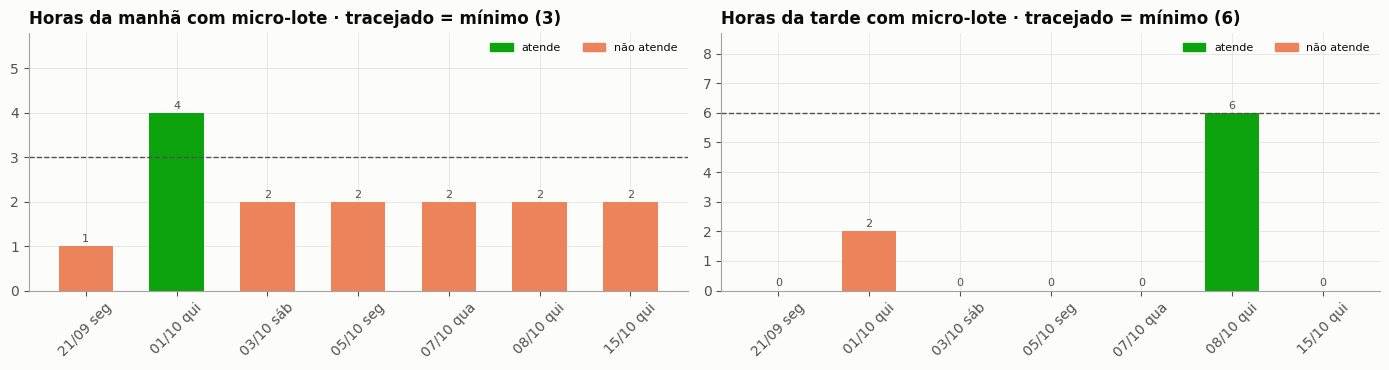

critério,necessário,encontrado,status
Dias completos (tarde inteira + manhã),≥ 14,0 de 7,❌ bloqueia
Dias seguidos com dados (lag de 24h),≥ 2,2,✅ ok
Horas com lag de 24h conhecido,maioria (≥ 50%),"4,3%",❌ bloqueia
Dias da semana cobertos,7,4,⚠️ atenção
Gerador ativo,micro-lote nas últimas 24 h,último há 24 dias,❌ bloqueia
Pedidos da manhã que chegam depois das 12h,o menor possível,"9,5%",⚠️ atenção
Receita em horas sem micro-lote (fora da grade),o menor possível,"9,1%",⚠️ atenção
Tabela íntegra e ligada (1.3 e 1.4),sem problema de chave,0 problemas,✅ ok


área,insight,uso no modelo
Volume,"14.196 itens em 2.375 pedidos, 7 dias com dados.",Suficiente para EDA e features; insuficiente para treinar o P1.
Valor do pedido,"valor_total = Σ qtd × preço − desconto por unidade (100,0%); frete fora.",valor_liquido e receita sem frete; frete como feature separada.
Qualidade,"4,9% de itens inválidos, todo dia.","Marcar com item_invalido; fora do mix e das médias, dentro da receita."
Categorias,3 maiores = 31% do valor; 123 categorias.,8 categorias + 'Outras' nas features de mix.
Mix manhã × tarde,"Até 27,2 p.p. de diferença (Outras).",Mix da manhã entra como feature do P1.
Catálogo,80% dos itens em 48% dos SKUs.,Cauda longa: relevante para o P2 (recomendação).
Cobertura do gerador,0 dias completos; parado há 24 dias.,"Bloqueia o treino do P1 até haver mais dias (decisão no 13_ml_features_itens, seção 3)."


📌 Leitura
   • Para EDA e features os dados são adequados: tabela íntegra, ligada e com a fórmula do valor conhecida.
   • Para treinar o P1 ainda não: 0 dias completos (mínimo 14), no máximo 2 dia(s) seguido(s) e gerador parado.


In [0]:
secao("1.9", "Os dados são adequados para o P1?")
cobertura = cobertura_dia.copy()
fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(14, 3.8), sharey=False)
for eixo, coluna, minimo, titulo in [(eixo1, "horas_manha_com_lote", MIN_HORAS_MANHA, "Horas da manhã com micro-lote"),
                                     (eixo2, "horas_tarde_com_lote", FIM_TARDE - HORA_PREVISAO, "Horas da tarde com micro-lote")]:
    atende = cobertura[coluna] >= minimo
    barras = eixo.bar([dia_txt(d) for d in cobertura["data"]], cobertura[coluna], color=[OK_COR if a else SERIO_COR for a in atende], width=0.6)
    rotular(eixo, barras, cobertura[coluna].astype(int).astype(str))
    eixo.axhline(minimo, color=TEXTO_2, linestyle="--", linewidth=1)
    eixo.set_ylim(0, max(minimo, cobertura[coluna].max()) * 1.45)
    eixo.set_title(f"{titulo} · tracejado = mínimo ({minimo})")
    eixo.tick_params(axis="x", rotation=45)
    eixo.legend(handles=[Patch(color=OK_COR, label="atende"), Patch(color=SERIO_COR, label="não atende")], fontsize=8, loc="upper right", ncol=2)
plt.tight_layout()
mostrar()

datas = pd.to_datetime(lotes["data"].drop_duplicates()).sort_values()
sequencia = (datas.diff().dt.days != 1).cumsum()
MAIOR_SEQUENCIA = int(sequencia.value_counts().max()) if len(datas) else 0
DIAS_SEMANA_COBERTOS = datas.dt.dayofweek.nunique()
manha_ped = pedidos[(pedidos["periodo"] == "manhã")]
tarde_chegada = 100 * (manha_ped["janela"] >= manha_ped["local"].dt.normalize() + pd.Timedelta(hours=HORA_PREVISAO)).mean() if len(manha_ped) else 0.0
criterios = pd.DataFrame([
    ("Dias completos (tarde inteira + manhã)", f"≥ {DIAS_MINIMOS_TREINO}", f"{DIAS_COMPLETOS} de {len(cobertura_dia)}", selo(DIAS_COMPLETOS >= DIAS_MINIMOS_TREINO, grave=True)),
    ("Dias seguidos com dados (lag de 24h)", "≥ 2", str(MAIOR_SEQUENCIA), selo(MAIOR_SEQUENCIA >= 2, grave=True)),
    ("Horas com lag de 24h conhecido", "maioria (≥ 50%)", pct(PCT_LAG24), selo(PCT_LAG24 >= 50, grave=True)),
    ("Dias da semana cobertos", "7", str(DIAS_SEMANA_COBERTOS), selo(DIAS_SEMANA_COBERTOS == 7)),
    ("Gerador ativo", "micro-lote nas últimas 24 h", f"último há {DIAS_SEM_DADO} dias", selo(DIAS_SEM_DADO <= 1, grave=True)),
    ("Pedidos da manhã que chegam depois das 12h", "o menor possível", pct(tarde_chegada), selo(tarde_chegada < 5)),
    ("Receita em horas sem micro-lote (fora da grade)", "o menor possível", pct(PCT_RECEITA_FORA), selo(PCT_RECEITA_FORA < 5)),
    ("Tabela íntegra e ligada (1.3 e 1.4)", "sem problema de chave", f"{N_DUP + N_CHAVE_VAZIA} problemas", selo(N_DUP + N_CHAVE_VAZIA == 0)),
], columns=["critério", "necessário", "encontrado", "status"])
exibir(criterios, "Critérios de adequação ao P1")

insights = pd.DataFrame([
    ("Volume", f"{br(len(itens))} itens em {br(len(pedidos))} pedidos, {DIAS_COM_DADO} dias com dados.", "Suficiente para EDA e features; insuficiente para treinar o P1."),
    ("Valor do pedido", f"valor_total = {MELHOR} ({pct(pct_conta[MELHOR])}); frete fora.", "valor_liquido e receita sem frete; frete como feature separada."),
    ("Qualidade", f"{pct(PCT_INVALIDOS)} de itens inválidos, todo dia.", "Marcar com item_invalido; fora do mix e das médias, dentro da receita."),
    ("Categorias", f"3 maiores = {pct(por_categoria['pct_valor'].head(3).sum(), 0)} do valor; {por_categoria.shape[0]} categorias.",
     f"{len(GRUPOS_MIX) - 1} categorias + 'Outras' nas features de mix."),
    ("Mix manhã × tarde", (f"Até {br(comparacao['diferenca_pp'].abs().max(), 1)} p.p. de diferença ({comparacao.loc[0, 'categoria']})." if tem_dois
                           else "Sem manhã e tarde para comparar."), "Mix da manhã entra como feature do P1."),
    ("Catálogo", f"80% dos itens em {pct(100 * SKUS_80 / len(vendas_sku), 0)} dos SKUs.", "Cauda longa: relevante para o P2 (recomendação)."),
    ("Cobertura do gerador", f"{DIAS_COMPLETOS} dias completos; parado há {DIAS_SEM_DADO} dias.", "Bloqueia o treino do P1 até haver mais dias (decisão no 13_ml_features_itens, seção 3)."),
], columns=["área", "insight", "uso no modelo"])
exibir(insights, "Insights da EDA")
leitura(f"Para EDA e features os dados são adequados: tabela íntegra, ligada e com a fórmula do valor conhecida.",
        f"Para treinar o P1 ainda não: {DIAS_COMPLETOS} dias completos (mínimo {DIAS_MINIMOS_TREINO}), no máximo {MAIOR_SEQUENCIA} dia(s) seguido(s) e gerador parado.")

---
# 3 · Conclusões da EDA

In [0]:
secao("3", "Conclusões da EDA")
print("🧭 O que a EDA mostrou")
print(f"   • Tabela de itens íntegra ({N_DUP + N_CHAVE_VAZIA} problemas de chave) e ligada a pedidos e catálogo ({pct(min(COB_PEDIDO, COB_SKU))}).")
print(f"   • valor_total = {MELHOR} em {pct(pct_conta[MELHOR])} dos pedidos; frete fora.")
print(f"   • {pct(PCT_INVALIDOS)} de itens inválidos: serão marcados (não apagados) nas features.")
print(f"   • 3 maiores categorias = {pct(por_categoria['pct_valor'].head(3).sum(), 0)} do valor"
      + (f"; mix muda até {br(comparacao['diferenca_pp'].abs().max(), 1)} p.p. entre manhã e tarde." if tem_dois else "."))
print(f"   • {len(insights)} insights para o modelo (seção 1.9).")
print("🚧 Para treinar o P1")
print(f"   • {DIAS_COMPLETOS} dias completos (mínimo {DIAS_MINIMOS_TREINO}), lag de 24h possível em {pct(PCT_LAG24)} das horas, gerador parado há {DIAS_SEM_DADO} dias.")
print("▶️ Próximo: 13_ml_features_itens (Tarefa 2 · engenharia de features).")

🧭 O que a EDA mostrou
   • Tabela de itens íntegra (0 problemas de chave) e ligada a pedidos e catálogo (100,0%).
   • valor_total = Σ qtd × preço − desconto por unidade em 100,0% dos pedidos; frete fora.
   • 4,9% de itens inválidos: serão marcados (não apagados) nas features.
   • 3 maiores categorias = 31% do valor; mix muda até 27,2 p.p. entre manhã e tarde.
   • 7 insights para o modelo (seção 1.9).
🚧 Para treinar o P1
   • 0 dias completos (mínimo 14), lag de 24h possível em 4,3% das horas, gerador parado há 24 dias.
▶️ Próximo: 13_ml_features_itens (Tarefa 2 · engenharia de features).


---
# 4 · Relatório da EDA
**Faz:** para cada etapa, junta **o que foi feito**, **o que obtivemos** (as leituras acima), a **interpretação** e o **impacto no modelo**, e grava em `docs/12_ml_eda_itens/` (o relatório não aparece no notebook). Salva também o `registro_eda.json`, que o `13_ml_features_itens` usa para montar o relatório completo.
**Valida:** que os arquivos foram gravados.

In [0]:
SECAO_ATUAL = None
FIM = pd.Timestamp.now(tz="America/Sao_Paulo").tz_localize(None)
DURACAO_S = time.time() - INICIO
contar = lambda serie, inicio: int(serie.astype(str).str.startswith(inicio).sum())


def interpretar_todas(funcoes):
    """Roda cada interpretação; uma etapa que falhou não impede o relatório das outras."""
    saida = {}
    for codigo, funcao in funcoes.items():
        try:
            saida[codigo] = funcao()
        except Exception as erro:
            saida[codigo] = ("—", f"Não foi possível interpretar nesta execução ({type(erro).__name__}: {erro}).", "—")
    return saida

def interpretar_0():
    ok, alerta, bloqueio = contar(respostas["status"], "✅"), contar(respostas["status"], "⚠️"), contar(respostas["status"], "❌")
    return ("Reúne os números-chave da base de itens e responde, com status, às perguntas da EDA.",
            f"{ok} das {len(respostas)} perguntas têm resposta positiva, {alerta} {'pede' if alerta == 1 else 'pedem'} atenção e "
            f"{bloqueio} {'bloqueia' if bloqueio == 1 else 'bloqueiam'}. "
            + ("O que bloqueia é o volume de dados para treinar o P1 — não a qualidade da tabela nem o código." if bloqueio else "Nada bloqueia o próximo passo."),
            "Mostra em um minuto que a EDA está concluída e onde está a pendência.")


def interpretar_1_1():
    janela = (ULTIMO_LOTE.normalize() - PRIMEIRO_LOTE.normalize()).days + 1
    return ("Lista todos os micro-lotes do raw/real-time-data e mapeia em que dias e horas o gerador rodou.",
            f"O gerador funcionou de forma intermitente: houve micro-lotes em {DIAS_COM_DADO} dos {janela} dias entre o primeiro e o último lote, "
            f"somando {len(horas_com_lote)} horas. Quando está ligado, gera um micro-lote a cada {br(intervalos.median(), 1)} min (granularidade boa para streaming). "
            f"Está parado há {DIAS_SEM_DADO} dias.",
            "Hora sem micro-lote é tratada como dado desconhecido (vazio), não como venda zero; o treino do P1 depende da volta do gerador ou de outra fonte histórica.")


def interpretar_1_2():
    return ("Descreve as colunas da tabela de itens: tipo, significado, vazios, faixa de valores e exemplos.",
            f"Tabela enxuta e bem tipada: {len(COLUNAS_ITENS)} colunas, uma linha por produto dentro do pedido — {br(len(itens))} linhas de "
            f"{br(itens['id_pedido'].nunique())} pedidos e {br(itens['sku'].nunique())} SKUs. "
            + ("Não há valores vazios." if perfil["vazios"].sum() == 0 else f"Há {br(perfil['vazios'].sum())} valores vazios."),
            "Sozinha, a tabela não tem hora nem categoria: as features dependem das ligações com pedidos (hora, valor) e com o catálogo (categoria).")


def interpretar_1_3():
    nivel = "baixo" if PCT_INVALIDOS < 1 else ("moderado" if PCT_INVALIDOS < 10 else "alto")
    com_problema = qualidade[qualidade["itens"] > 0]
    lista = ", ".join(f"{r} ({br(n)})" for r, n in zip(com_problema["regra"], com_problema["itens"])) or "nenhuma regra"
    return ("Aplica as regras básicas de um item (chaves, duplicidade, quantidade, preço e desconto) e mede quanto cada problema representa.",
            f"Nível {nivel} de sujeira: {pct(PCT_INVALIDOS)} dos itens são inválidos. Problemas encontrados: {lista}. "
            f"Atingem {pct(100 * len(afetados) / len(pedidos))} dos pedidos. Como o valor_total já inclui esses itens "
            f"(a conta fecha em {pct(bate_afetados)} desses pedidos), apagá-los quebraria a conferência da receita.",
            "Nas features (13_ml_features_itens), a marca item_invalido e a feature n_itens_invalidos; os inválidos ficam fora do mix e das médias, mas dentro da receita.")


def interpretar_1_4():
    return ("Confere se cada chave encontra o seu par (pedido, produto, categoria), se o item chega no mesmo micro-lote do pedido e o destino dos pedidos no pipeline.",
            ("Todas as chaves encontram par" if (ligacoes["cobertura_pct"] >= 99).all() else "Há ligações abaixo de 99%")
            + f" e {pct(ligacoes.loc[2, 'cobertura_pct'])} dos itens chegam no mesmo micro-lote do pedido. "
            f"{pct(100 * destino['aprovado (Silver)'] / destino.sum())} dos pedidos foram aprovados pelo pipeline; {br(destino['quarentena'])} estão em quarentena.",
            "As features podem ser calculadas no mesmo ciclo de polling, sem esperar outro lote; a receita usa só pedidos aprovados, coerente com a Silver e os KPIs.")


def interpretar_1_5():
    return ("Testa 8 contas possíveis para reproduzir o valor_total a partir dos itens (com e sem desconto, desconto por linha, por unidade ou em %, com e sem frete).",
            f"A conta que reproduz o valor_total é '{MELHOR}', em {pct(pct_conta[MELHOR])} dos pedidos. Ou seja: o desconto_aplicado é por unidade "
            + ("e o frete não faz parte do valor_total." if MELHOR == MELHOR_BASE else "e o frete faz parte do valor_total."),
            "valor_liquido = Σ quantidade × (preço − desconto) é igual ao valor_total (vira teste de qualidade); o frete entra como coluna separada.")


def interpretar_1_6():
    media, mediana = por_pedido["valor_total"].mean(), por_pedido["valor_total"].median()
    return ("Mede a distribuição de itens por pedido, quantidade, preço unitário, desconto, valor do pedido e frete.",
            f"O pedido típico tem {br(por_pedido['n_itens'].median())} itens e vale {reais(mediana)} (mediana). A média ({reais(media)}) é "
            f"{br(media / mediana, 2)}× a mediana: "
            + ("poucos pedidos grandes puxam a média para cima. " if media / mediana > 1.2 else "distribuição pouco assimétrica. ")
            + f"O preço unitário tem cauda longa "
            f"(5% dos itens acima de {reais(precos.quantile(.95))}).",
            "Distribuições assimétricas: usar mediana nos resumos e considerar log do valor em modelos lineares; o LightGBM do P1 lida bem com caudas.")


def interpretar_1_7():
    n_grupos = len(GRUPOS_MIX) - 1
    pct_grupos = por_categoria["pct_valor"].head(n_grupos).sum()
    return ("Liga cada item ao catálogo e mede o peso das categorias, a cobertura do catálogo e a concentração por SKU (Pareto).",
            f"Vendas espalhadas: {por_categoria.shape[0]} categorias vendem; as 3 maiores somam {pct(por_categoria['pct_valor'].head(3).sum(), 0)} e as "
            f"{n_grupos} com coluna própria somam {pct(pct_grupos, 0)}. 80% dos itens vêm de {pct(100 * SKUS_80 / len(vendas_sku), 0)} dos SKUs. "
            + ("Como 'Outras' ainda concentra mais de 40% do valor, vale testar mais categorias ou agrupar pelo departamento (nome_categoria_pai)."
               if 100 - pct_grupos > 40 else ""),
            f"Mix com {n_grupos} categorias + Outras nas features do P1; a cauda longa de SKUs é relevante para a recomendação (P2).")


def interpretar_1_8():
    texto = (f"O pico de pedidos é às {int(observadas['pedidos_por_hora'].idxmax())}h e o ticket médio varia de {reais(observadas['ticket_medio'].min())} "
             f"a {reais(observadas['ticket_medio'].max())} entre as horas. ")
    if tem_dois:
        maior = comparacao.iloc[0]
        texto += (f"O mix muda entre manhã e tarde: {maior['categoria']} vai de {pct(maior['manha_pct'])} para {pct(maior['tarde_pct'])} "
                  f"({br(maior['diferenca_pp'], 1)} p.p.). ")
    texto += f"{pct(PCT_RECEITA_FORA)} da receita aprovada cai em horas sem micro-lote e fica fora da grade horária."
    return ("Compara horas pela média por hora observada (pedidos, ticket) e o mix de categorias da manhã com o da tarde.", texto,
            "O mix da manhã carrega informação sobre a tarde e virou feature do P1 (pct_valor_<categoria>_manha). Os padrões por hora ainda são indicativos.")


def interpretar_1_9():
    bloqueios = criterios.loc[criterios["status"].astype(str).str.startswith("❌"), "critério"].tolist()
    return ("Confronta os dados com o que o P1 precisa: dias completos (tarde inteira + manhã), dias seguidos para o lag de 24h e gerador ativo.",
            "Os dados são adequados para EDA e features (íntegros, ligados e com a fórmula do valor conhecida), "
            + (f"mas ainda não para treinar o P1. Bloqueiam: {'; '.join(bloqueios)}." if bloqueios else "e também para treinar o P1."),
            "A pendência é de volume de dados e leva à decisão A/B/C (13_ml_features_itens, seção 3).")


def celula_texto(valor, markdown=False):
    texto = br(valor, 2) if isinstance(valor, float) else str(valor).replace("\n", " ")
    return texto.replace("|", "\\|") if markdown else texto        # "|" quebraria a tabela markdown


def tabela_md(tabela):
    colunas = [celula_texto(c, markdown=True) for c in tabela.columns]
    linhas = ["| " + " | ".join(colunas) + " |", "|" + "---|" * len(colunas)]
    linhas += ["| " + " | ".join(celula_texto(v, markdown=True) for v in linha) + " |" for linha in tabela.itertuples(index=False)]
    return "\n".join(linhas)


def tabela_html(tabela):
    cabecalho = "".join(f"<th>{html_lib.escape(str(c))}</th>" for c in tabela.columns)
    corpo = "".join("<tr>" + "".join(f"<td>{html_lib.escape(celula_texto(v))}</td>" for v in linha) + "</tr>" for linha in tabela.itertuples(index=False))
    return f'<div class="rolagem"><table><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table></div>'


def cartoes_tabela(lista):
    estado = {"ok": "✅", "alerta": "⚠️", "erro": "❌", None: ""}
    return pd.DataFrame([(r, v, n, estado[e]) for r, v, n, e in lista], columns=["indicador", "valor", "detalhe", "status"])


ESTILO = """<style>
body{font-family:-apple-system,Segoe UI,Roboto,sans-serif;background:#fcfcfb;color:#0b0b0b;margin:0;padding:24px 16px;line-height:1.5}
main{max-width:1100px;margin:0 auto} h1{font-size:26px;margin:0 0 8px} h2{margin-top:36px;border-bottom:2px solid #2a78d6;padding-bottom:4px}
h3{margin-top:28px} .info{color:#52514e;font-size:14px} section{border-top:1px solid #e4e3df;padding-top:8px} h2+section{border-top:none}
.interp{background:#eef4fc;border-left:4px solid #2a78d6;padding:8px 12px} .impacto{background:#f4f3f0;border-left:4px solid #a3a29c;padding:8px 12px}
.rotulo{font-weight:600;margin-bottom:4px} .rolagem{overflow-x:auto} table{border-collapse:collapse;font-size:13px;margin:6px 0 14px}
th,td{border:1px solid #e4e3df;padding:4px 8px;text-align:left;vertical-align:top} th{background:#f0efec}
img{max-width:100%;border:1px solid #e4e3df;margin:8px 0}
</style>"""


def montar_relatorio(titulo, nome_notebook, subpasta, ordem, registro, interpretacao, partes, cabecalho_info, extra_md=(), extra_html=""):
    """Monta o relatório (.md e .html com gráficos), grava em docs/<subpasta>/ e atualiza o indice.md. Devolve (pasta, arquivos gravados)."""
    md = [f"# 📊 {titulo}", "", *[f"- **{k}:** {v}" for k, v in cabecalho_info], "",
          f"> Relatório gerado automaticamente a cada execução do `{nome_notebook}`. Os números vêm das execuções indicadas acima. "
          "Os gráficos estão no arquivo `.html` de mesmo nome.", ""]
    secoes_html, parte_atual = [], None
    for codigo in ordem:
        reg = registro[codigo]
        feito, interp, impacto = interpretacao.get(codigo, ("—", "—", "—"))
        parte = codigo.split(".")[0]
        if parte != parte_atual:                        # título da parte (no resumo, ele já é o título da seção)
            parte_atual = parte
            md += ["---", f"## {partes[parte]}", ""]
            secoes_html.append(f"<h2>{partes[parte]}</h2>")
        blocos = []
        if "." in codigo:
            titulo_secao = f"{codigo} · {reg['titulo']}"
            md += [f"### {titulo_secao}", ""]
            blocos.append(f"<h3>{html_lib.escape(titulo_secao)}</h3>")
        md += [f"**O que foi feito:** {feito}", ""]
        blocos.append(f"<p><b>O que foi feito:</b> {html_lib.escape(feito)}</p>")
        if reg.get("cartoes"):
            md += [tabela_md(cartoes_tabela(reg["cartoes"])), ""]
            blocos.append(tabela_html(cartoes_tabela(reg["cartoes"])))
        if reg.get("leituras"):
            md += ["**O que obtivemos:**", "", *[f"- {l}" for l in reg["leituras"]], ""]
            blocos.append("<p><b>O que obtivemos:</b></p><ul>" + "".join(f"<li>{html_lib.escape(l)}</li>" for l in reg["leituras"]) + "</ul>")
        md += [f"**Interpretação:** {interp}", "", f"**Impacto no modelo:** {impacto}", ""]
        blocos += [f'<p class="interp"><b>Interpretação:</b> {html_lib.escape(interp)}</p>',
                   f'<p class="impacto"><b>Impacto no modelo:</b> {html_lib.escape(impacto)}</p>']
        for nome, tabela in reg.get("tabelas", []):
            md += [f"**{nome}**", "", tabela_md(tabela), ""]
            blocos += [f"<p class='rotulo'>{html_lib.escape(nome)}</p>", tabela_html(tabela)]
        blocos += [f'<img src="data:image/png;base64,{f}" alt="gráfico da seção {codigo}">' for f in reg.get("figuras", [])]
        secoes_html.append(f'<section>{"".join(blocos)}</section>')
    md += list(extra_md)
    info = "".join(f"<div><b>{html_lib.escape(k)}:</b> {html_lib.escape(v)}</div>" for k, v in cabecalho_info)
    html = (f'<!doctype html><html lang="pt-BR"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">'
            f"<title>{html_lib.escape(titulo)} · {FIM:%m/%d/%Y %H:%M:%S}</title>{ESTILO}</head><body><main>"
            f'<h1>📊 {html_lib.escape(titulo)}</h1><div class="info">{info}</div>{"".join(secoes_html)}{extra_html}</main></body></html>')

    pasta, gravados = pasta_docs(subpasta), []
    if pasta:
        nome_base = f"relatorio_{FIM:%m-%d-%Y_%H-%M-%S}"
        try:
            os.makedirs(pasta, exist_ok=True)
            for extensao, conteudo in [("md", "\n".join(md)), ("html", html)]:
                with open(os.path.join(pasta, f"{nome_base}.{extensao}"), "w", encoding="utf-8") as arquivo:
                    arquivo.write(conteudo)
                gravados.append(f"{nome_base}.{extensao}")
            execucoes = sorted((f for f in os.listdir(pasta) if re.fullmatch(r"relatorio_.+\.md", f)),
                               key=lambda f: pd.to_datetime(f[10:-3], format="%m-%d-%Y_%H-%M-%S"), reverse=True)
            with open(os.path.join(pasta, "indice.md"), "w", encoding="utf-8") as arquivo:
                arquivo.write(f"# 📚 Execuções do {nome_notebook}\n\nMais recente primeiro. Cada execução tem um `.md` (texto) e um `.html` (com gráficos).\n\n"
                              + "\n".join(f"- {pd.to_datetime(f[10:-3], format='%m-%d-%Y_%H-%M-%S'):%m/%d/%Y %H:%M:%S} · [{f}]({f}) · {f[:-3]}.html"
                                          for f in execucoes) + "\n")
        except OSError as erro:
            print(f"⚠️ Não foi possível gravar em {pasta}: {erro}")
    checar(len(gravados) == 2, f"Relatório gravado em {pasta}: {', '.join(gravados)} (+ indice.md)",
           "Relatório não gravado: o texto aparece abaixo", parar=False)
    if gravados:                                       # o relatório fica só em docs/, não no notebook
        print("📝 Relatório desta execução (abra na pasta docs/):")
        for arquivo in gravados + ["indice.md"]:
            print(f"   • {pasta}/{arquivo}")
    else:
        print("\n".join(md)[:3000])
    return pasta, gravados


ORDEM = [c for c in ["0", "1.1", "1.2", "1.3", "1.4", "1.5", "1.6", "1.7", "1.8", "1.9"] if c in REGISTRO]
interpretacao = interpretar_todas({c: globals()[f"interpretar_{c.replace('.', '_')}"] for c in ["0", "1.1", "1.2", "1.3", "1.4", "1.5",
                                                                                                 "1.6", "1.7", "1.8", "1.9"]})
proximo_md = ["---", "## ▶️ Próximo passo", "",
              "Rodar o `13_ml_features_itens` (Tarefa 2): ele cria as features a partir destas descobertas, valida tudo contra a planilha "
              "e gera o relatório completo (EDA + features) em `docs/13_ml_features_itens/`.", ""]
pasta_eda, _ = montar_relatorio(
    "Relatório · EDA da base de itens", "12_ml_eda_itens", "12_ml_eda_itens", ORDEM, REGISTRO, interpretacao,
    {"0": "0 · Resumo da EDA", "1": "Parte 1 · Análise exploratória (EDA)"},
    [("Gerado em", f"{FIM:%m/%d/%Y} às {FIM:%H:%M:%S} (Brasília)"), ("Duração da execução", f"{br(DURACAO_S, 0)} s"),
     ("Notebook", "12_ml_eda_itens · Tarefa 1 · Análise exploratória"), ("Dupla", "Squad 2 · Eduardo e Aliedson"),
     ("Base da etapa 1", "ecommerce_itens_pedido"), ("Problema", "P1 · previsão de vendas da tarde (LightGBM com lags)"),
     ("Fonte", "raw/real-time-data (streaming) + Silver")],
    proximo_md, "<h2>▶️ Próximo passo</h2><p>Rodar o <code>13_ml_features_itens</code> (Tarefa 2): ele cria as features a partir destas descobertas, "
                "valida tudo contra a planilha e gera o relatório completo (EDA + features) em <code>docs/13_ml_features_itens/</code>.</p>")

# ------------------------------ registro da EDA para o 13_ml_features_itens ------------------------------
def tabela_json(tabela):
    tabela = tabela.copy()
    tabela.columns = [str(c) for c in tabela.columns]
    return {"colunas": list(tabela.columns), "linhas": tabela.astype(object).where(tabela.notna(), None).values.tolist()}


EDA_METRICAS = {
    "n_itens": int(len(itens)), "n_pedidos": int(len(pedidos)), "n_lotes": int(len(lotes)), "n_lotes_itens": int(len(por_tabela["itens"])),
    "primeiro_lote": f"{PRIMEIRO_LOTE:%d/%m}", "ultimo_lote": f"{ULTIMO_LOTE:%d/%m}", "dias_sem_dado": int(DIAS_SEM_DADO),
    "n_dup": int(N_DUP), "n_chave_vazia": int(N_CHAVE_VAZIA), "cob_pedido": float(COB_PEDIDO), "cob_sku": float(COB_SKU),
    "pct_invalidos": float(PCT_INVALIDOS), "n_colunas_perfil": int(len(perfil)), "n_colunas_itens": int(len(COLUNAS_ITENS)),
    "melhor_conta": MELHOR, "pct_melhor": float(pct_conta[MELHOR]), "n_categorias": int(por_categoria.shape[0]),
    "skus_vendidos": int(len(vendas_sku)), "top3_pct": float(por_categoria["pct_valor"].head(3).sum()), "n_insights": int(len(insights)),
    "mix_max_pp": float(comparacao["diferenca_pp"].abs().max()) if tem_dois else None,
    "mix_categoria": str(comparacao.loc[0, "categoria"]) if tem_dois else None,
    "mediana_itens_pedido": float(por_pedido["n_itens"].median()), "mediana_valor_pedido": float(por_pedido["valor_total"].median()),
    "dias_completos": int(DIAS_COMPLETOS), "pct_lag24": float(PCT_LAG24)}
registro_eda = {"gerado_em": f"{FIM:%m/%d/%Y %H:%M:%S}", "metricas": EDA_METRICAS,
                "interpretacao": {c: list(v) for c, v in interpretacao.items()},
                "registro": {c: {"titulo": REGISTRO[c]["titulo"], "leituras": REGISTRO[c]["leituras"], "figuras": REGISTRO[c]["figuras"],
                                 "cartoes": [list(x) for x in REGISTRO[c]["cartoes"]],
                                 "tabelas": [[n, tabela_json(t)] for n, t in REGISTRO[c]["tabelas"]]} for c in ORDEM}}
if pasta_eda:
    try:
        with open(os.path.join(pasta_eda, "registro_eda.json"), "w", encoding="utf-8") as arquivo:
            json.dump(registro_eda, arquivo, ensure_ascii=False, default=str)
        checar(True, f"Registro da EDA salvo para o 13_ml_features_itens: {pasta_eda}/registro_eda.json", "")
    except OSError as erro:
        checar(False, "", f"Registro da EDA não gravado ({erro}): o relatório do 13 sairá sem a Parte 1", parar=False)

✅ Relatório gravado em /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/12_ml_eda_itens: relatorio_11-08-2026_02-55-15.md, relatorio_11-08-2026_02-55-15.html (+ indice.md)
📝 Relatório desta execução (abra na pasta docs/):
   • /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/12_ml_eda_itens/relatorio_11-08-2026_02-55-15.md
   • /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/12_ml_eda_itens/relatorio_11-08-2026_02-55-15.html
   • /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/12_ml_eda_itens/indice.md
✅ Registro da EDA salvo para o 13_ml_features_itens: /Workspace/Users/eduardogeraldoo@gmail.com/6-squad2_ecommerce_real_time - Claude/docs/12_ml_eda_itens/registro_eda.json


# 📘 Documentação · 🔍 12_ml_eda_itens - Análise exploratória da base de itens

## 📌 Projeto: Real-Time Ecommerce Analytics · ML em Streaming

**Squad:** Squad 2 · Eduardo e Aliedson
**Base da etapa 1:** itens (`ecommerce_itens_pedido`)
**Problema da dupla:** P1 · Previsão de vendas do período da tarde (LightGBM com lags)
**Tarefa:** 1 · Análise exploratória dos dados

---

## 🎯 Objetivo

Entender se os dados estão adequados, conhecer a tabela de itens e gerar insights para o modelo do P1. Não grava dados.

---

## 🗂️ Fontes

```text
raw/real-time-data/AAAA/MM/DD/HHMMSS/
├── ecommerce_itens_pedido.parquet     base da dupla
├── ecommerce_pedidos.parquet          hora e valor do pedido
├── ecommerce_produtos.parquet         sku → categoria e marca
└── ecommerce_categorias.parquet       nome da categoria
squad2/silver/ecommerce_pedidos        pedidos aprovados
squad2/quarantine/ecommerce_pedidos    pedidos em quarentena
```

---

## 📝 Saída de cada execução

```text
docs/12_ml_eda_itens/
├── relatorio_MM-DD-AAAA_HH-MM-SS.md     o que foi feito, o que obtivemos, interpretação e impacto, por etapa
├── relatorio_MM-DD-AAAA_HH-MM-SS.html   o mesmo conteúdo com os gráficos
├── indice.md                            todas as execuções
└── registro_eda.json                    resultados desta execução, usados pelo 13_ml_features_itens
```

Data no formato mês/dia/ano e horário em horas, minutos e segundos (Brasília).

---

## 🔄 Ordem dos notebooks de ML

```text
12_ml_eda_itens       Tarefa 1 · EDA (este notebook)
        │
        ▼
13_ml_features_itens  Tarefa 2 · features + validação + relatório completo
```

---

## 🧾 Parâmetros

```text
HORA_PREVISAO / FIM_TARDE     12h / 18h (tarde do P1)
MIN_HORAS_MANHA               3 horas da manhã com micro-lote para o dia ser completo
DIAS_MINIMOS_TREINO           14 dias completos (duas semanas) como mínimo para treinar e testar
TOP_CATEGORIAS                8 categorias com coluna própria no mix (o resto vira "Outras")
TOLERANCIA_VALOR              R$ 0,05 na comparação itens × valor_total
```